In [ ]:
!unzip -oq quantized-bitflip-study.zip -d /content
%cd /content/quantized-bitflip-study
!python -m pytest -q tests

/content/quantized-bitflip-study
................                                                         [100%]
16 passed in 5.79s


100%|██████████| 9.91M/9.91M [00:01<00:00, 5.56MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 160kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.52MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 1.62MB/s]


FP32 clean accuracy: 96.39
fp32 clean accuracy: 96.39
int8 clean accuracy: 96.38
int4 clean accuracy: 96.27
440 trials saved to results/day1_bit_sweep.csv


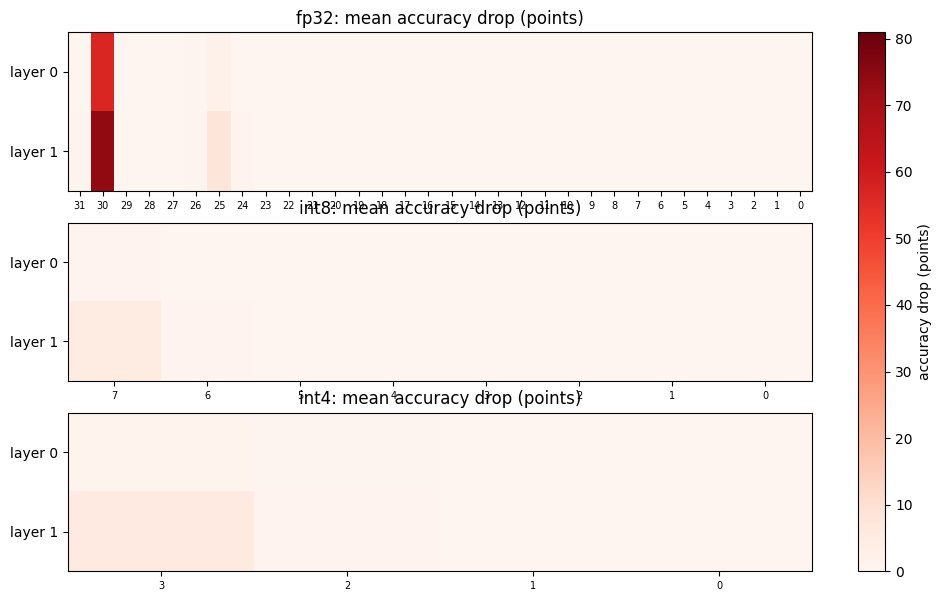

int8 - mean accuracy drop (points)
bit      0     1     2     3     4     5     6     7
layer                                               
0      0.0  0.01  0.02  0.02 -0.02  0.09  0.24  0.73
1      0.0 -0.00  0.02  0.02  0.04  0.20  0.75  4.13 

int4 - mean accuracy drop (points)
bit       0     1     2     3
layer                        
0      0.04  0.17  0.46  1.11
1      0.03  0.13  0.95  5.22 



In [ ]:
import os
os.chdir("/content/quantized-bitflip-study")   # make sure we are inside the project

import torch
import pandas as pd
import matplotlib.pyplot as plt
from src.eval import load_mnist, make_mlp, train, accuracy, corrupt_model, linear_layers
from src.quant import NBITS

# --- Step 1: train the baseline model ---
torch.manual_seed(0)
train_dl, test_dl = load_mnist()
model = train(make_mlp(), train_dl, epochs=3)
print("FP32 clean accuracy:", accuracy(model, test_dl))
torch.save(model.state_dict(), "results/mlp_mnist_fp32.pt")

# --- Step 2: clean accuracy in each format (no bit flips) ---
for fmt in NBITS:
    print(fmt, "clean accuracy:", round(accuracy(corrupt_model(model, fmt), test_dl), 2))

# --- Step 3: flip one bit position at a time (2% of a layer's weights, 5 seeds) ---
FRAC, SEEDS = 0.02, range(5)
rows = []
for fmt, nbits in NBITS.items():
    clean = accuracy(corrupt_model(model, fmt), test_dl)
    for layer in range(len(linear_layers(model))):
        for bit in range(nbits):
            for seed in SEEDS:
                gen = torch.Generator().manual_seed(seed)
                m = corrupt_model(model, fmt, [layer], "bit", gen, bit=bit, frac=FRAC)
                acc = accuracy(m, test_dl)
                rows.append(dict(model="mlp", dataset="mnist", fmt=fmt, layer=layer, bit=bit,
                                 seed=seed, frac=FRAC, clean_acc=clean, acc=acc, drop=clean - acc))
df = pd.DataFrame(rows)
df.to_csv("results/day1_bit_sweep.csv", index=False)
print(len(df), "trials saved to results/day1_bit_sweep.csv")

# --- Step 4: heatmaps (sign bit on the left) ---
vmax = df["drop"].max()
fig, axes = plt.subplots(3, 1, figsize=(12, 7))
for ax, fmt in zip(axes, NBITS):
    t = df[df.fmt == fmt].pivot_table(index="layer", columns="bit", values="drop", aggfunc="mean")
    t = t[sorted(t.columns, reverse=True)]
    im = ax.imshow(t.values, cmap="Reds", aspect="auto", vmin=0, vmax=vmax)
    ax.set_xticks(range(t.shape[1])); ax.set_xticklabels(t.columns, fontsize=7)
    ax.set_yticks(range(t.shape[0])); ax.set_yticklabels([f"layer {l}" for l in t.index])
    ax.set_title(f"{fmt}: mean accuracy drop (points)")
fig.colorbar(im, ax=axes, label="accuracy drop (points)")
plt.savefig("figures/day1_heatmaps.png", dpi=200, bbox_inches="tight")
plt.show()

for fmt in ["int8", "int4"]:
    print(fmt, "- mean accuracy drop (points)")
    print(df[df.fmt == fmt].pivot_table(index="layer", columns="bit", values="drop", aggfunc="mean").round(2), "\n")

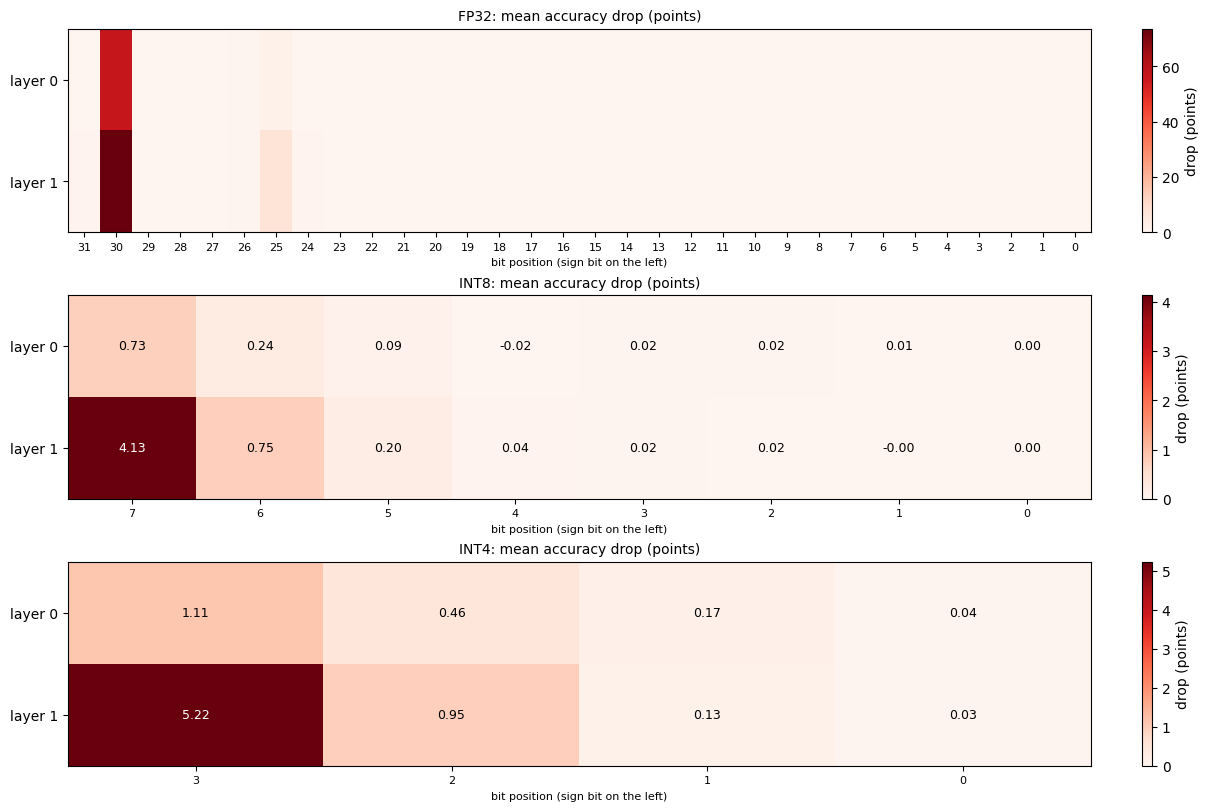

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 1, figsize=(12, 8), constrained_layout=True)
for ax, fmt in zip(axes, ["fp32", "int8", "int4"]):
    t = df[df.fmt == fmt].pivot_table(index="layer", columns="bit", values="drop", aggfunc="mean")
    t = t[sorted(t.columns, reverse=True)]                  # sign bit on the left
    vmax = max(t.values.max(), 1.0)                         # own colour scale for each format
    im = ax.imshow(t.values, cmap="Reds", aspect="auto", vmin=0, vmax=vmax)
    ax.set_xticks(range(t.shape[1])); ax.set_xticklabels(t.columns, fontsize=8)
    ax.set_yticks(range(t.shape[0])); ax.set_yticklabels([f"layer {l}" for l in t.index])
    ax.set_xlabel("bit position (sign bit on the left)", fontsize=8)
    ax.set_title(f"{fmt.upper()}: mean accuracy drop (points)", fontsize=10)
    if t.shape[1] <= 8:                                     # write numbers inside INT8/INT4 cells
        for i in range(t.shape[0]):
            for j in range(t.shape[1]):
                v = t.values[i, j]
                ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=9,
                        color="white" if v > 0.6 * vmax else "black")
    fig.colorbar(im, ax=ax, label="drop (points)")
plt.savefig("figures/day1_heatmaps_fixed.png", dpi=200, bbox_inches="tight")
plt.show()

In [ ]:
import copy
import torch
import torch.nn as nn
from torchvision import datasets

# ---------- data (MNIST downloads automatically) ----------
tr = datasets.MNIST("data", train=True, download=True)
te = datasets.MNIST("data", train=False, download=True)
Xtr, Ytr = (tr.data.float() / 255).unsqueeze(1), tr.targets
Xte, Yte = (te.data.float() / 255).unsqueeze(1), te.targets

# ---------- CNN (LeNet-style, ~61k parameters) ----------
torch.manual_seed(0)
cnn = nn.Sequential(
    nn.Conv2d(1, 6, 5, padding=2), nn.ReLU(), nn.MaxPool2d(2),
    nn.Conv2d(6, 16, 5), nn.ReLU(), nn.MaxPool2d(2),
    nn.Flatten(),
    nn.Linear(400, 120), nn.ReLU(),
    nn.Linear(120, 84), nn.ReLU(),
    nn.Linear(84, 10),
)
opt = torch.optim.Adam(cnn.parameters(), lr=1e-3)
g_train = torch.Generator().manual_seed(0)
for epoch in range(3):
    perm = torch.randperm(len(Xtr), generator=g_train)
    for i in range(0, len(Xtr), 128):
        idx = perm[i:i + 128]
        opt.zero_grad()
        nn.functional.cross_entropy(cnn(Xtr[idx]), Ytr[idx]).backward()
        opt.step()


def acc(m):
    """Test accuracy in percent."""
    with torch.no_grad():
        return 100 * (m(Xte).argmax(1) == Yte).float().mean().item()


# ---------- quantization and bit flips ----------
NB = {"fp32": 32, "int8": 8, "int4": 4}
LAYER_NAMES = ["conv1", "conv2", "fc1", "fc2", "fc3"]


def wlayers(m):
    """Conv2d and Linear layers, in network order."""
    return [x for x in m.modules() if isinstance(x, (nn.Conv2d, nn.Linear))]


def quantize(w, fmt):
    if fmt == "fp32":
        return w.clone(), torch.tensor(1.0)
    qmax = 2 ** (NB[fmt] - 1) - 1
    scale = w.abs().max() / qmax
    return torch.clamp(torch.round(w / scale), -(qmax + 1), qmax).to(torch.int8), scale


def flip_bit(q, fmt, bit, frac, gen):
    """Flip bit `bit` (0 = least significant) in a random `frac` of the stored weights."""
    flat = q.reshape(-1)
    idx = torch.randperm(flat.numel(), generator=gen)[:int(frac * flat.numel())]
    masks = torch.zeros(flat.numel(), dtype=torch.int64)
    masks[idx] = 1 << bit
    if fmt == "fp32":
        out = (flat.contiguous().view(torch.int32) ^ masks.to(torch.int32)).view(torch.float32)
    else:
        nb = NB[fmt]
        raw = (flat.to(torch.int64) & ((1 << nb) - 1)) ^ masks
        out = torch.where(raw >= (1 << (nb - 1)), raw - (1 << nb), raw).to(torch.int8)
    return out.reshape(q.shape)


def build(model, fmt, layer=None, bit=None, frac=0.02, gen=None):
    """Copy of `model` with all weights stored in `fmt`; if `layer` is given,
    flip `bit` in `frac` of that layer's weights. Biases are left untouched."""
    m = copy.deepcopy(model)
    for li, lay in enumerate(wlayers(m)):
        q, s = quantize(lay.weight.data, fmt)
        if li == layer:
            q = flip_bit(q, fmt, bit, frac, gen)
        lay.weight.data = q if fmt == "fp32" else q.float() * s
    return m


print("CNN parameters:", sum(p.numel() for p in cnn.parameters()))
for fmt in NB:
    print(f"{fmt} clean accuracy: {acc(build(cnn, fmt)):.2f}")

100%|██████████| 9.91M/9.91M [00:00<00:00, 22.3MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 599kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 5.55MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.81MB/s]


CNN parameters: 61706
fp32 clean accuracy: 98.00
int8 clean accuracy: 97.98
int4 clean accuracy: 98.00


fp32 done
int8 done
int4 done
1100 trials saved to cnn_bit_sweep.csv


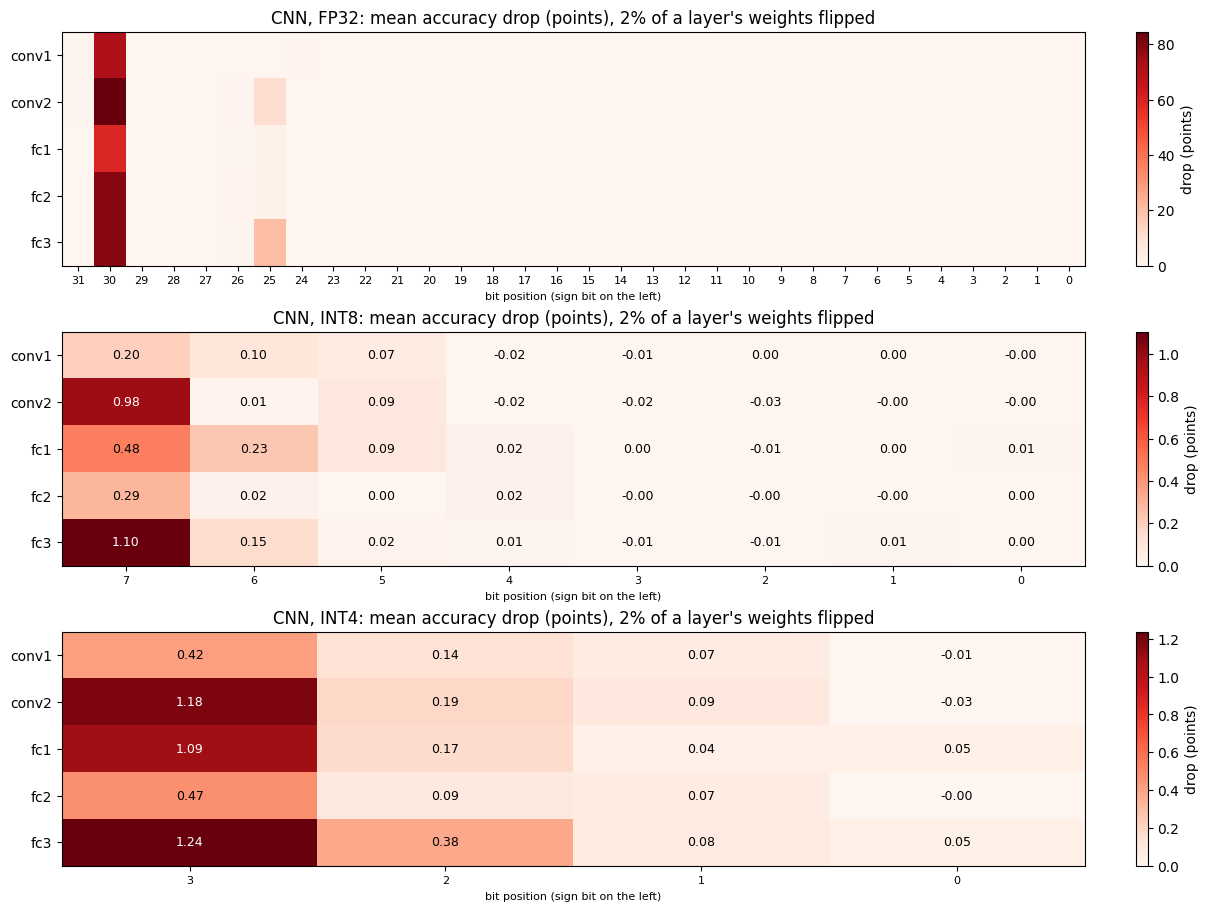

       fp32 bit30 mean  fp32 std  int8 bit7 mean  int8 std  int4 bit3 mean  int4 std
conv1            71.16     22.62            0.20      0.24            0.42      0.17
conv2            84.50     11.32            0.98      0.75            1.18      0.62
fc1              58.46     14.10            0.48      0.53            1.09      0.25
fc2              78.92      4.57            0.29      0.34            0.47      0.37
fc3              79.00      7.95            1.10      0.52            1.24      0.46


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

FRAC, SEEDS = 0.02, range(5)
rows = []
for fmt, nbits in NB.items():
    clean = acc(build(cnn, fmt))
    for layer in range(5):
        for bit in range(nbits):
            for seed in SEEDS:
                gen = torch.Generator().manual_seed(seed)
                a = acc(build(cnn, fmt, layer, bit, FRAC, gen))
                rows.append(dict(model="cnn", dataset="mnist", fmt=fmt, layer=layer, bit=bit,
                                 seed=seed, frac=FRAC, clean_acc=clean, acc=a, drop=clean - a))
    print(fmt, "done")
df_cnn = pd.DataFrame(rows)
df_cnn.to_csv("cnn_bit_sweep.csv", index=False)
print(len(df_cnn), "trials saved to cnn_bit_sweep.csv")

# ---------- heatmaps (own colour scale per format) ----------
fig, axes = plt.subplots(3, 1, figsize=(12, 9), constrained_layout=True)
for ax, fmt in zip(axes, NB):
    t = df_cnn[df_cnn.fmt == fmt].pivot_table(index="layer", columns="bit", values="drop", aggfunc="mean")
    t = t[sorted(t.columns, reverse=True)]
    vmax = max(t.values.max(), 1.0)
    im = ax.imshow(t.values, cmap="Reds", aspect="auto", vmin=0, vmax=vmax)
    ax.set_xticks(range(t.shape[1])); ax.set_xticklabels(t.columns, fontsize=8)
    ax.set_yticks(range(5)); ax.set_yticklabels(LAYER_NAMES)
    ax.set_xlabel("bit position (sign bit on the left)", fontsize=8)
    ax.set_title(f"CNN, {fmt.upper()}: mean accuracy drop (points), {FRAC * 100:.0f}% of a layer's weights flipped")
    if t.shape[1] <= 8:
        for i in range(t.shape[0]):
            for j in range(t.shape[1]):
                v = t.values[i, j]
                ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=9,
                        color="white" if v > 0.6 * vmax else "black")
    fig.colorbar(im, ax=ax, label="drop (points)")
plt.savefig("cnn_heatmaps.png", dpi=200, bbox_inches="tight")
plt.show()

# ---------- worst bit per layer: mean and std over 5 seeds ----------
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)
top = {"fp32": 30, "int8": 7, "int4": 3}          # FP32 exponent MSB, INT sign bits
parts = []
for fmt, bit in top.items():
    g = df_cnn[(df_cnn.fmt == fmt) & (df_cnn.bit == bit)].groupby("layer").drop.agg(["mean", "std"]).round(2)
    g.index = LAYER_NAMES
    g.columns = [f"{fmt} bit{bit} mean", f"{fmt} std"]
    parts.append(g)
print(pd.concat(parts, axis=1))

from google.colab import files
files.download("cnn_bit_sweep.csv")
files.download("cnn_heatmaps.png")

In [ ]:
import pandas as pd
from google.colab import files
up = files.upload()                      # choose cnn_bit_sweep.csv in the dialog
df_cnn = pd.read_csv("cnn_bit_sweep.csv")
print(df_cnn.shape, df_cnn.fmt.value_counts().to_dict())

Saving cnn_bit_sweep.csv to cnn_bit_sweep.csv
(1100, 10) {'fp32': 800, 'int8': 200, 'int4': 100}


In [ ]:
import copy
import torch
import torch.nn as nn
from torchvision import datasets

# ---------- data (MNIST downloads automatically) ----------
tr = datasets.MNIST("data", train=True, download=True)
te = datasets.MNIST("data", train=False, download=True)
Xtr, Ytr = (tr.data.float() / 255).unsqueeze(1), tr.targets
Xte, Yte = (te.data.float() / 255).unsqueeze(1), te.targets
# ---------- end data ----------

# ---------- CNN (LeNet-style, ~61k parameters) ----------
torch.manual_seed(0)
cnn = nn.Sequential(
    nn.Conv2d(1, 6, 5, padding=2), nn.ReLU(), nn.MaxPool2d(2),
    nn.Conv2d(6, 16, 5), nn.ReLU(), nn.MaxPool2d(2),
    nn.Flatten(),
    nn.Linear(400, 120), nn.ReLU(),
    nn.Linear(120, 84), nn.ReLU(),
    nn.Linear(84, 10),
)
opt = torch.optim.Adam(cnn.parameters(), lr=1e-3)
g_train = torch.Generator().manual_seed(0)
for epoch in range(3):
    perm = torch.randperm(len(Xtr), generator=g_train)
    for i in range(0, len(Xtr), 128):
        idx = perm[i:i + 128]
        opt.zero_grad()
        nn.functional.cross_entropy(cnn(Xtr[idx]), Ytr[idx]).backward()
        opt.step()


def acc(m):
    """Test accuracy in percent."""
    with torch.no_grad():
        return 100 * (m(Xte).argmax(1) == Yte).float().mean().item()


# ---------- quantization and bit flips ----------
NB = {"fp32": 32, "int8": 8, "int4": 4}
LAYER_NAMES = ["conv1", "conv2", "fc1", "fc2", "fc3"]


def wlayers(m):
    """Conv2d and Linear layers, in network order."""
    return [x for x in m.modules() if isinstance(x, (nn.Conv2d, nn.Linear))]


def quantize(w, fmt):
    if fmt == "fp32":
        return w.clone(), torch.tensor(1.0)
    qmax = 2 ** (NB[fmt] - 1) - 1
    scale = w.abs().max() / qmax
    return torch.clamp(torch.round(w / scale), -(qmax + 1), qmax).to(torch.int8), scale


def flip_bit(q, fmt, bit, frac, gen):
    """Flip bit `bit` (0 = least significant) in a random `frac` of the stored weights."""
    flat = q.reshape(-1)
    idx = torch.randperm(flat.numel(), generator=gen)[:int(frac * flat.numel())]
    masks = torch.zeros(flat.numel(), dtype=torch.int64)
    masks[idx] = 1 << bit
    if fmt == "fp32":
        out = (flat.contiguous().view(torch.int32) ^ masks.to(torch.int32)).view(torch.float32)
    else:
        nb = NB[fmt]
        raw = (flat.to(torch.int64) & ((1 << nb) - 1)) ^ masks
        out = torch.where(raw >= (1 << (nb - 1)), raw - (1 << nb), raw).to(torch.int8)
    return out.reshape(q.shape)


def build(model, fmt, layer=None, bit=None, frac=0.02, gen=None):
    """Copy of `model` with all weights stored in `fmt`; if `layer` is given,
    flip `bit` in `frac` of that layer's weights. Biases are left untouched."""
    m = copy.deepcopy(model)
    for li, lay in enumerate(wlayers(m)):
        q, s = quantize(lay.weight.data, fmt)
        if li == layer:
            q = flip_bit(q, fmt, bit, frac, gen)
        lay.weight.data = q if fmt == "fp32" else q.float() * s
    return m


print("CNN parameters:", sum(p.numel() for p in cnn.parameters()))
for fmt in NB:
    print(f"{fmt} clean accuracy: {acc(build(cnn, fmt)):.2f}")

100%|██████████| 9.91M/9.91M [00:00<00:00, 18.9MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 501kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.66MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.89MB/s]


CNN parameters: 61706
fp32 clean accuracy: 98.00
int8 clean accuracy: 97.98
int4 clean accuracy: 98.00


fp32: most sensitive bits, worst first: [30, 25, 26, 24]
int8: most sensitive bits, worst first: [7, 6, 5, 4]
int4: most sensitive bits, worst first: [3, 2, 1, 0]
fp32 done
int8 done
int4 done
 fmt   ber         config  extra_storage_pct  mean   std
fp32 0.001        M0 none                0.0 10.75  4.17
fp32 0.001 M1 parity-zero                3.1 58.67 37.73
fp32 0.001  M2 top-1 bits                6.2 95.84  2.75
fp32 0.001  M2 top-2 bits               12.5 97.62  0.33
fp32 0.001  M2 top-3 bits               18.8 97.69  0.21
fp32 0.010        M0 none                0.0  9.80  0.00
fp32 0.010 M1 parity-zero                3.1  9.80  0.00
fp32 0.010  M2 top-1 bits                6.2 42.79 22.04
fp32 0.010  M2 top-2 bits               12.5 88.19 10.36
fp32 0.010  M2 top-3 bits               18.8 92.42  8.66
int4 0.001        M0 none                0.0 97.64  0.33
int4 0.001 M1 parity-zero               25.0 97.96  0.10
int4 0.001  M2 top-1 bits               50.0 97.87  0.16
int4 0.00

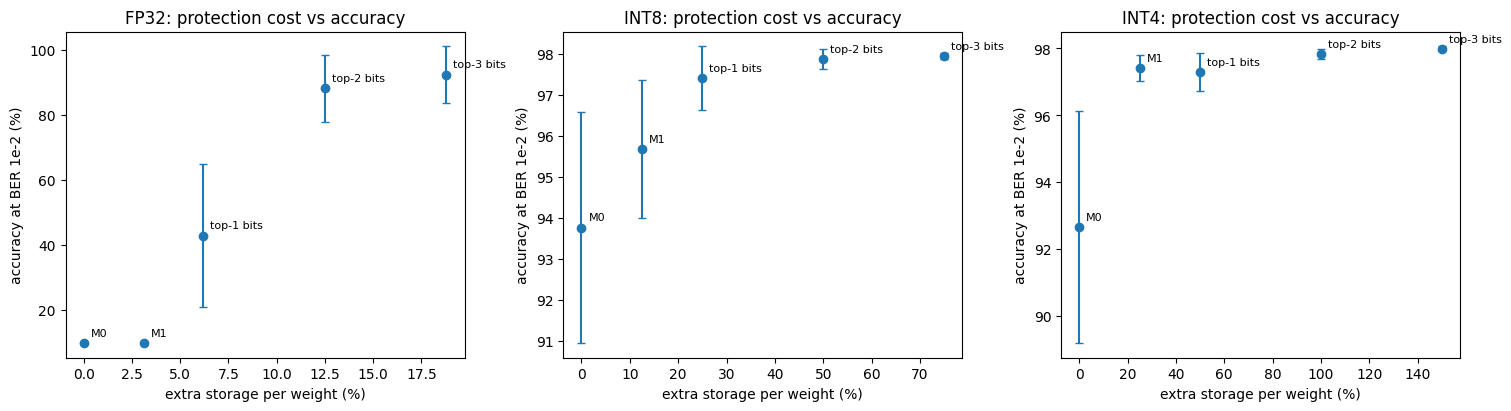

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ===== CODE 4: M2 - protect only the top-k most sensitive bit positions =====
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def corrupt_prot(model, fmt, ber, seed, protected=(), parity=False):
    """Random bit faults over ALL weights (every stored bit flips with probability `ber`).
    protected : bit positions that are shielded (e.g. by TMR / ECC) and are NEVER flipped.
    parity    : also use parity-zero (M1), same as in Code 3.
    The same seed gives the same random numbers for every setting, so comparisons are fair."""
    nb = NB[fmt]
    gen = torch.Generator().manual_seed(seed)
    m = copy.deepcopy(model)
    for lay in wlayers(m):
        q, s = quantize(lay.weight.data, fmt)
        flat = q.reshape(-1)
        hits = torch.rand(flat.numel(), nb + 1, generator=gen) < ber      # last column = parity bit
        for b in protected:
            hits[:, b] = False                                           # shielded bits never flip
        mask = (hits[:, :nb].long() << torch.arange(nb)).sum(1)
        if fmt == "fp32":
            mask32 = torch.where(mask >= 2 ** 31, mask - 2 ** 32, mask).to(torch.int32)
            out = (flat.contiguous().view(torch.int32) ^ mask32).view(torch.float32)
        else:
            raw = (flat.to(torch.int64) & ((1 << nb) - 1)) ^ mask
            out = torch.where(raw >= (1 << (nb - 1)), raw - (1 << nb), raw).to(torch.int8)
        if parity:
            out = torch.where(hits.sum(1) % 2 == 1, torch.zeros_like(out), out)
        out = out.reshape(q.shape)
        lay.weight.data = out if fmt == "fp32" else out.float() * s
    return m


# Which bits are most sensitive? Rank bit positions by the mean drop in the bit sweep (df_cnn).
rank = {f: list(df_cnn[df_cnn.fmt == f].groupby("bit").drop.mean().sort_values(ascending=False).index)
        for f in NB}
for f in NB:
    print(f"{f}: most sensitive bits, worst first: {rank[f][:4]}")

BERS, SEEDS, KS = [1e-3, 1e-2], range(10), [1, 2, 3]
rows = []
for fmt in NB:
    nb = NB[fmt]
    clean = acc(build(cnn, fmt))
    configs = [("M0 none", (), False, 0.0), ("M1 parity-zero", (), True, 100 / nb)]
    for k in KS:   # TMR assumption: each protected bit needs 2 extra copies -> 2k extra bits per weight
        configs.append((f"M2 top-{k} bits", tuple(rank[fmt][:k]), False, 200 * k / nb))
    for ber in BERS:
        for name, prot, par, extra in configs:
            for seed in SEEDS:
                rows.append(dict(fmt=fmt, ber=ber, config=name, extra_storage_pct=round(extra, 1), seed=seed,
                                 clean=clean, acc=acc(corrupt_prot(cnn, fmt, ber, seed, prot, par))))
    print(fmt, "done")
dfm2 = pd.DataFrame(rows)
dfm2.to_csv("cnn_topk_protection.csv", index=False)

pd.set_option("display.width", 200)
tab = dfm2.groupby(["fmt", "ber", "config", "extra_storage_pct"]).acc.agg(["mean", "std"]).round(2).reset_index()
print(tab.to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
for ax, fmt in zip(axes, NB):
    t = tab[(tab.fmt == fmt) & (tab.ber == 1e-2)]
    ax.errorbar(t.extra_storage_pct, t["mean"], t["std"], fmt="o", capsize=3)
    for _, r in t.iterrows():
        ax.annotate(r.config.split(" ", 1)[1] if r.config.startswith("M2") else r.config.split()[0],
                    (r.extra_storage_pct, r["mean"]), textcoords="offset points", xytext=(5, 5), fontsize=8)
    ax.set_xlabel("extra storage per weight (%)")
    ax.set_ylabel("accuracy at BER 1e-2 (%)")
    ax.set_title(f"{fmt.upper()}: protection cost vs accuracy")
plt.savefig("cnn_topk_protection.png", dpi=200, bbox_inches="tight")
plt.show()

from google.colab import files
files.download("cnn_topk_protection.csv")
files.download("cnn_topk_protection.png")

INT4 layer sensitivity (higher = more fragile):
  fc3    1.75
  conv2  1.44
  fc1    1.35
  fc2    0.62
  conv1  0.62
all INT4 done
mixed: 2 most sensitive in INT8 done
control: 2 LEAST sensitive in INT8 done
mixed: 3 most sensitive in INT8 done
all INT8 done
                            config  size_kb   ber  clean  mean  std
                          all INT4     30.0 0.001  98.00 97.66 0.46
                          all INT4     30.0 0.010  98.00 91.58 3.47
                          all INT8     60.0 0.001  97.98 97.71 0.18
                          all INT8     60.0 0.010  97.98 95.09 1.58
control: 2 LEAST sensitive in INT8     35.0 0.001  97.98 97.94 0.18
control: 2 LEAST sensitive in INT8     35.0 0.010  97.98 94.27 2.63
   mixed: 2 most sensitive in INT8     31.6 0.001  98.05 97.81 0.20
   mixed: 2 most sensitive in INT8     31.6 0.010  98.05 95.53 1.12
   mixed: 3 most sensitive in INT8     55.0 0.001  97.97 97.89 0.21
   mixed: 3 most sensitive in INT8     55.0 0.010  97.97 95.

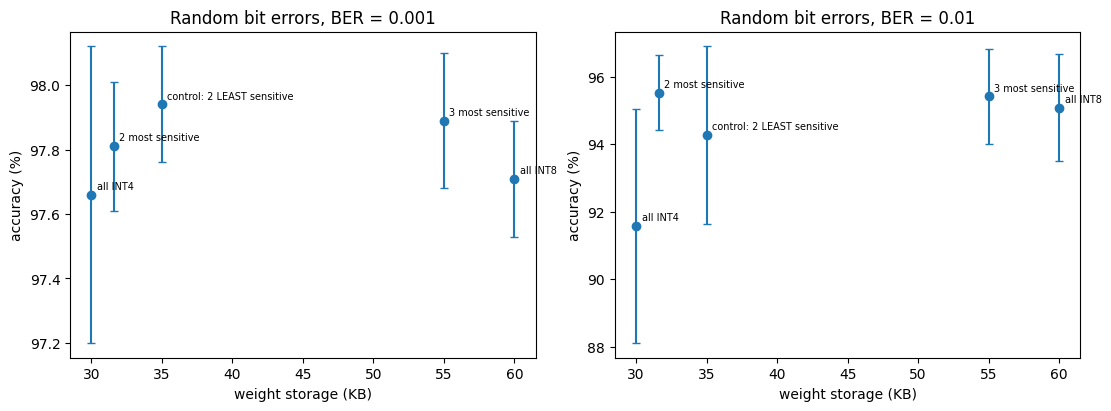

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ===== CODE 5: M3 - mixed precision by layer (Kai's idea: sensitive layers INT8, the rest INT4) =====
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def corrupt_mixed(model, fmts, ber, seed):
    """`fmts` = one format name per weight layer, e.g. ["int8","int8","int4","int4","int4"].
    Every stored bit flips with probability `ber` (ber=0 gives the clean quantized model)."""
    gen = torch.Generator().manual_seed(seed)
    m = copy.deepcopy(model)
    for lay, fmt in zip(wlayers(m), fmts):
        nb = NB[fmt]
        q, s = quantize(lay.weight.data, fmt)
        flat = q.reshape(-1)
        hits = torch.rand(flat.numel(), nb, generator=gen) < ber
        mask = (hits.long() << torch.arange(nb)).sum(1)
        if fmt == "fp32":
            mask32 = torch.where(mask >= 2 ** 31, mask - 2 ** 32, mask).to(torch.int32)
            out = (flat.contiguous().view(torch.int32) ^ mask32).view(torch.float32)
        else:
            raw = (flat.to(torch.int64) & ((1 << nb) - 1)) ^ mask
            out = torch.where(raw >= (1 << (nb - 1)), raw - (1 << nb), raw).to(torch.int8)
        out = out.reshape(q.shape)
        lay.weight.data = out if fmt == "fp32" else out.float() * s
    return m


# Layer sensitivity = sum over bit positions of the mean accuracy drop (INT4 sweep).
sens = (df_cnn[df_cnn.fmt == "int4"].groupby(["layer", "bit"]).drop.mean()
        .groupby("layer").sum().sort_values(ascending=False))
order = list(sens.index)                                   # most sensitive layer first
print("INT4 layer sensitivity (higher = more fragile):")
for l in order:
    print(f"  {LAYER_NAMES[l]:6s} {sens[l]:.2f}")

n = len(LAYER_NAMES)
sizes = [lay.weight.numel() for lay in wlayers(cnn)]


def cfg(int8_layers):
    return ["int8" if l in int8_layers else "int4" for l in range(n)]


configs = {
    "all INT4": cfg([]),
    "mixed: 2 most sensitive in INT8": cfg(order[:2]),
    "control: 2 LEAST sensitive in INT8": cfg(order[-2:]),
    "mixed: 3 most sensitive in INT8": cfg(order[:3]),
    "all INT8": cfg(range(n)),
}
BERS, SEEDS = [1e-3, 1e-2], range(10)
rows = []
for name, fm in configs.items():
    kb = sum(sz * NB[f] for sz, f in zip(sizes, fm)) / 8 / 1024
    clean = acc(corrupt_mixed(cnn, fm, 0.0, 0))
    for ber in BERS:
        for seed in SEEDS:
            rows.append(dict(config=name, size_kb=round(kb, 1), ber=ber, seed=seed, clean=clean,
                             acc=acc(corrupt_mixed(cnn, fm, ber, seed))))
    print(name, "done")
dfm3 = pd.DataFrame(rows)
dfm3.to_csv("cnn_mixed_precision.csv", index=False)

pd.set_option("display.width", 200)
tab = dfm3.groupby(["config", "size_kb", "ber"]).agg(clean=("clean", "first"), mean=("acc", "mean"),
                                                      std=("acc", "std")).round(2).reset_index()
print(tab.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
for ax, ber in zip(axes, BERS):
    t = tab[tab.ber == ber]
    ax.errorbar(t.size_kb, t["mean"], t["std"], fmt="o", capsize=3)
    for _, r in t.iterrows():
        ax.annotate(r.config.replace("mixed: ", "").replace(" in INT8", ""), (r.size_kb, r["mean"]),
                    textcoords="offset points", xytext=(4, 4), fontsize=7)
    ax.set_xlabel("weight storage (KB)")
    ax.set_ylabel("accuracy (%)")
    ax.set_title(f"Random bit errors, BER = {ber:g}")
plt.savefig("cnn_mixed_precision.png", dpi=200, bbox_inches="tight")
plt.show()

from google.colab import files
files.download("cnn_mixed_precision.csv")
files.download("cnn_mixed_precision.png")

In [ ]:
# ===== CODE 6: Verilog parity-zero checker + testbench (Icarus Verilog, runs inside Colab) =====
import subprocess

print(subprocess.run("apt-get -qq install -y iverilog yosys > /dev/null 2>&1; iverilog -V | head -1",
                     shell=True, capture_output=True, text=True).stdout)

open("parity_zero.v", "w").write("""\
// Parity-zero read path. `stored` = N data bits + 1 even-parity bit (bit N).
// A fault-free word has an even number of ones, so ^stored = 0.
// If an ODD number of bits flipped, ^stored = 1 -> the weight is read as 0.
module parity_zero #(parameter N = 8) (
    input  [N:0]   stored,
    output [N-1:0] weight,
    output         err
);
    assign err    = ^stored;
    assign weight = err ? {N{1'b0}} : stored[N-1:0];
endmodule
""")

open("tb_parity_zero.v", "w").write("""\
`timescale 1ns/1ps
module tb;
    parameter N = 8;
    reg  [N:0]   stored;
    reg  [N:0]   base;
    wire [N-1:0] weight;
    wire         err;
    reg  [N-1:0] data;
    integer d, i, j;
    integer ok0, bad0, ok1, bad1, ok2, bad2, silent2;
    parity_zero #(.N(N)) dut (.stored(stored), .weight(weight), .err(err));
    initial begin
        ok0 = 0; bad0 = 0; ok1 = 0; bad1 = 0; ok2 = 0; bad2 = 0; silent2 = 0;
        for (d = 0; d < (1 << N); d = d + 1) begin
            data = d;
            base = {^data, data};                       // even parity bit
            stored = base; #1;                          // no fault
            if (weight === data && err === 1'b0) ok0 = ok0 + 1; else bad0 = bad0 + 1;
            for (i = 0; i <= N; i = i + 1) begin        // every single flip
                stored = base ^ ({{N{1'b0}}, 1'b1} << i); #1;
                if (weight === {N{1'b0}} && err === 1'b1) ok1 = ok1 + 1; else bad1 = bad1 + 1;
            end
            for (i = 0; i <= N; i = i + 1)              // every double flip
                for (j = i + 1; j <= N; j = j + 1) begin
                    stored = base ^ ({{N{1'b0}}, 1'b1} << i) ^ ({{N{1'b0}}, 1'b1} << j); #1;
                    if (err === 1'b0 && weight === stored[N-1:0]) ok2 = ok2 + 1; else bad2 = bad2 + 1;
                    if (weight !== data) silent2 = silent2 + 1;
                end
        end
        $display("N=%0d | no fault      : %0d ok, %0d wrong", N, ok0, bad0);
        $display("N=%0d | single flips   : %0d ok (read as 0), %0d wrong", N, ok1, bad1);
        $display("N=%0d | double flips   : %0d pass through undetected, %0d wrong", N, ok2, bad2);
        $display("N=%0d | double flips that corrupt the weight silently: %0d", N, silent2);
        if (bad0 == 0 && bad1 == 0 && bad2 == 0) $display("N=%0d RESULT: ALL TESTS PASSED", N);
        else $display("N=%0d RESULT: FAILED", N);
        $finish;
    end
endmodule
""")

for N in (4, 8):
    r = subprocess.run(f"iverilog -g2012 -P tb.N={N} -o sim{N} tb_parity_zero.v parity_zero.v && vvp sim{N}",
                       shell=True, capture_output=True, text=True)
    print(r.stdout + r.stderr)

Icarus Verilog version 12.0 (stable) ()

N=4 | no fault      : 16 ok, 0 wrong
N=4 | single flips   : 80 ok (read as 0), 0 wrong
N=4 | double flips   : 160 pass through undetected, 0 wrong
N=4 | double flips that corrupt the weight silently: 160
N=4 RESULT: ALL TESTS PASSED
tb_parity_zero.v:36: $finish called at 256000 (1ps)

N=8 | no fault      : 256 ok, 0 wrong
N=8 | single flips   : 2304 ok (read as 0), 0 wrong
N=8 | double flips   : 9216 pass through undetected, 0 wrong
N=8 | double flips that corrupt the weight silently: 9216
N=8 RESULT: ALL TESTS PASSED
tb_parity_zero.v:36: $finish called at 11776000 (1ps)



In [ ]:
# ===== CODE 7: Yosys - relative logic cost of the parity-zero checker =====
import re
import subprocess
import pandas as pd

# A reference block to compare against: one N x N multiplier (what a MAC spends per weight).
open("mult_ref.v", "w").write("""\
module mult_ref #(parameter N = 8) (input [N-1:0] a, input [N-1:0] b, output [2*N-1:0] p);
    assign p = a * b;
endmodule
""")


def yosys_cells(top, n, script="synth"):
    cmd = (f'yosys -q -p "read_verilog parity_zero.v mult_ref.v; chparam -set N {n} {top}; '
           f'{script} -top {top}; tee -o stat.txt stat"')
    subprocess.run(cmd, shell=True, capture_output=True, text=True)
    txt = open("stat.txt").read()
    m = re.search(r"(\d+)\s+cells", txt) or re.search(r"Number of cells:\s+(\d+)", txt)
    return int(m.group(1)) if m else None


rows = []
for fmt, n in [("INT4", 4), ("INT8", 8), ("FP32", 32)]:
    pz = yosys_cells("parity_zero", n)
    lut = yosys_cells("parity_zero", n, "synth_ice40")
    mul = yosys_cells("mult_ref", n)
    rows.append(dict(format=fmt, data_bits=n, parity_zero_gates=pz, parity_zero_LUT4=lut,
                     multiplier_gates=mul,
                     checker_vs_multiplier_pct=round(100 * pz / mul, 1) if pz and mul else None,
                     storage_overhead_pct=round(100 / n, 1)))
res = pd.DataFrame(rows)
pd.set_option("display.width", 200)
print(res.to_string(index=False))
res.to_csv("yosys_parity_cells.csv", index=False)
print("\nNote: these are generic-gate / LUT4 counts from Yosys, a RELATIVE estimate, not signed-off silicon area.")

from google.colab import files
files.download("yosys_parity_cells.csv")

format  data_bits  parity_zero_gates  parity_zero_LUT4  multiplier_gates  checker_vs_multiplier_pct  storage_overhead_pct
  INT4          4                  8                 6                69                       11.6                  25.0
  INT8          8                 16                11               354                        4.5                  12.5
  FP32         32                 64                43              6405                        1.0                   3.1

Note: these are generic-gate / LUT4 counts from Yosys, a RELATIVE estimate, not signed-off silicon area.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ===== CODE 8: layer x bit sweep with 10 seeds + 95% bootstrap confidence intervals =====
# Re-runs the sweep on the CNN of THIS notebook (so every result comes from one model). Takes ~20-30 minutes.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

FRAC, SEEDS = 0.02, range(10)
rows = []
for fmt, nbits in NB.items():
    clean = acc(build(cnn, fmt))
    for layer in range(5):
        for bit in range(nbits):
            for seed in SEEDS:
                gen = torch.Generator().manual_seed(seed)
                a = acc(build(cnn, fmt, layer, bit, FRAC, gen))
                rows.append(dict(model="cnn", dataset="mnist", fmt=fmt, layer=layer, bit=bit,
                                 seed=seed, frac=FRAC, clean_acc=clean, acc=a, drop=clean - a))
    pd.DataFrame(rows).to_csv("cnn_bit_sweep_10seeds.csv", index=False)     # checkpoint after each format
    print(fmt, "done")
df10 = pd.DataFrame(rows)


def boot_ci(x, n=2000, seed=0):
    """95% bootstrap confidence interval of the mean."""
    x = np.asarray(x, dtype=float)
    r = np.random.default_rng(seed)
    means = x[r.integers(0, len(x), (n, len(x)))].mean(1)
    return np.percentile(means, 2.5), np.percentile(means, 97.5)


ci_rows = []
for (fmt, layer, bit), g in df10.groupby(["fmt", "layer", "bit"]):
    lo, hi = boot_ci(g["drop"])
    ci_rows.append(dict(fmt=fmt, layer=LAYER_NAMES[layer], bit=bit, mean_drop=g["drop"].mean(),
                        ci_low=lo, ci_high=hi))
ci = pd.DataFrame(ci_rows).round(2)
ci.to_csv("cnn_bit_ci.csv", index=False)

pd.set_option("display.width", 200)
print("\nCells whose 95% CI lower end is above 1 accuracy point (clearly harmful):")
bad = ci[ci.ci_low > 1.0].sort_values("mean_drop", ascending=False)
print(f"{len(bad)} of {len(ci)} (format, layer, bit) cells")
print(bad.groupby("fmt").size().to_string())

print("\nWorst bit per format, per layer (mean drop with 95% CI):")
for fmt, bit in {"fp32": 30, "int8": 7, "int4": 3}.items():
    t = ci[(ci.fmt == fmt) & (ci.bit == bit)][["layer", "mean_drop", "ci_low", "ci_high"]]
    print(f"\n{fmt.upper()} bit {bit}")
    print(t.to_string(index=False))

# heatmaps, own colour scale per format (same style as before)
fig, axes = plt.subplots(3, 1, figsize=(12, 9), constrained_layout=True)
for ax, fmt in zip(axes, NB):
    t = df10[df10.fmt == fmt].pivot_table(index="layer", columns="bit", values="drop", aggfunc="mean")
    t = t[sorted(t.columns, reverse=True)]
    vmax = max(t.values.max(), 1.0)
    im = ax.imshow(t.values, cmap="Reds", aspect="auto", vmin=0, vmax=vmax)
    ax.set_xticks(range(t.shape[1])); ax.set_xticklabels(t.columns, fontsize=8)
    ax.set_yticks(range(5)); ax.set_yticklabels(LAYER_NAMES)
    ax.set_xlabel("bit position (sign bit on the left)", fontsize=8)
    ax.set_title(f"CNN, {fmt.upper()}: mean accuracy drop (points), 10 seeds, {FRAC * 100:.0f}% of a layer flipped")
    if t.shape[1] <= 8:
        for i in range(t.shape[0]):
            for j in range(t.shape[1]):
                v = t.values[i, j]
                ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=9,
                        color="white" if v > 0.6 * vmax else "black")
    fig.colorbar(im, ax=ax, label="drop (points)")
plt.savefig("cnn_heatmaps_10seeds.png", dpi=200, bbox_inches="tight")
plt.show()

from google.colab import files
files.download("cnn_bit_sweep_10seeds.csv")
files.download("cnn_bit_ci.csv")
files.download("cnn_heatmaps_10seeds.png")

KeyboardInterrupt: 

In [ ]:
# ===== CODE 8: layer x bit sweep with 10 seeds + 95% bootstrap confidence intervals =====
# Re-runs the sweep on the CNN of THIS notebook (so every result comes from one model). Takes ~20-30 minutes.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

FRAC, SEEDS = 0.02, range(10)
rows = []
for fmt, nbits in NB.items():
    clean = acc(build(cnn, fmt))
    for layer in range(5):
        for bit in range(nbits):
            for seed in SEEDS:
                gen = torch.Generator().manual_seed(seed)
                a = acc(build(cnn, fmt, layer, bit, FRAC, gen))
                rows.append(dict(model="cnn", dataset="mnist", fmt=fmt, layer=layer, bit=bit,
                                 seed=seed, frac=FRAC, clean_acc=clean, acc=a, drop=clean - a))
    pd.DataFrame(rows).to_csv("cnn_bit_sweep_10seeds.csv", index=False)     # checkpoint after each format
    print(fmt, "done")
df10 = pd.DataFrame(rows)


def boot_ci(x, n=2000, seed=0):
    """95% bootstrap confidence interval of the mean."""
    x = np.asarray(x, dtype=float)
    r = np.random.default_rng(seed)
    means = x[r.integers(0, len(x), (n, len(x)))].mean(1)
    return np.percentile(means, 2.5), np.percentile(means, 97.5)


ci_rows = []
for (fmt, layer, bit), g in df10.groupby(["fmt", "layer", "bit"]):
    lo, hi = boot_ci(g["drop"])
    ci_rows.append(dict(fmt=fmt, layer=LAYER_NAMES[layer], bit=bit, mean_drop=g["drop"].mean(),
                        ci_low=lo, ci_high=hi))
ci = pd.DataFrame(ci_rows).round(2)
ci.to_csv("cnn_bit_ci.csv", index=False)

pd.set_option("display.width", 200)
print("\nCells whose 95% CI lower end is above 1 accuracy point (clearly harmful):")
bad = ci[ci.ci_low > 1.0].sort_values("mean_drop", ascending=False)
print(f"{len(bad)} of {len(ci)} (format, layer, bit) cells")
print(bad.groupby("fmt").size().to_string())

print("\nWorst bit per format, per layer (mean drop with 95% CI):")
for fmt, bit in {"fp32": 30, "int8": 7, "int4": 3}.items():
    t = ci[(ci.fmt == fmt) & (ci.bit == bit)][["layer", "mean_drop", "ci_low", "ci_high"]]
    print(f"\n{fmt.upper()} bit {bit}")
    print(t.to_string(index=False))

# heatmaps, own colour scale per format (same style as before)
fig, axes = plt.subplots(3, 1, figsize=(12, 9), constrained_layout=True)
for ax, fmt in zip(axes, NB):
    t = df10[df10.fmt == fmt].pivot_table(index="layer", columns="bit", values="drop", aggfunc="mean")
    t = t[sorted(t.columns, reverse=True)]
    vmax = max(t.values.max(), 1.0)
    im = ax.imshow(t.values, cmap="Reds", aspect="auto", vmin=0, vmax=vmax)
    ax.set_xticks(range(t.shape[1])); ax.set_xticklabels(t.columns, fontsize=8)
    ax.set_yticks(range(5)); ax.set_yticklabels(LAYER_NAMES)
    ax.set_xlabel("bit position (sign bit on the left)", fontsize=8)
    ax.set_title(f"CNN, {fmt.upper()}: mean accuracy drop (points), 10 seeds, {FRAC * 100:.0f}% of a layer flipped")
    if t.shape[1] <= 8:
        for i in range(t.shape[0]):
            for j in range(t.shape[1]):
                v = t.values[i, j]
                ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=9,
                        color="white" if v > 0.6 * vmax else "black")
    fig.colorbar(im, ax=ax, label="drop (points)")
plt.savefig("cnn_heatmaps_10seeds.png", dpi=200, bbox_inches="tight")
plt.show()

from google.colab import files
files.download("cnn_bit_sweep_10seeds.csv")
files.download("cnn_bit_ci.csv")
files.download("cnn_heatmaps_10seeds.png")

KeyboardInterrupt: 

int8 per-tensor done
int8 per-channel done
int4 per-tensor done
int4 per-channel done
Mean accuracy drop (points) when exponent bit 30 of a scale factor flips:
layer             conv1  conv2    fc1    fc2    fc3
fmt  scale                                         
int4 per-channel  88.07  88.04  64.52  51.73  29.35
     per-tensor   88.20  88.20  88.20  88.20  73.36
int8 per-channel  87.75  88.16  63.71  52.32  30.06
     per-tensor   88.18  88.18  88.18  88.18  73.55


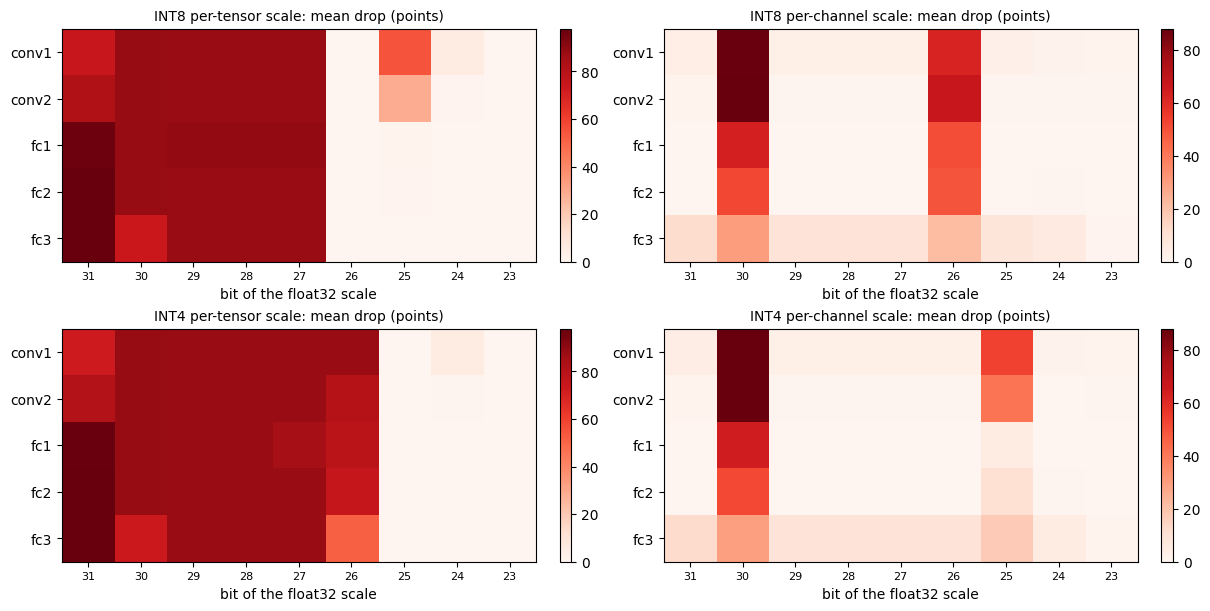

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ===== CODE 10 (optional): faults in the SCALE FACTOR - per-tensor vs per-channel quantization =====
# INT weights are stored as integers plus a float32 scale. A flip in the scale hits every weight that uses it.
# per-tensor : one scale per layer  -> a flip changes the whole layer.
# per-channel: one scale per output channel -> a flip changes only that channel.
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def quant_pc(w, fmt, per_channel):
    qmax = 2 ** (NB[fmt] - 1) - 1
    if per_channel:
        scale = w.abs().flatten(1).max(1).values / qmax                     # one scale per output channel
        sh = (-1,) + (1,) * (w.dim() - 1)
        q = torch.clamp(torch.round(w / scale.view(sh)), -(qmax + 1), qmax)
        return q, scale, sh
    scale = w.abs().max() / qmax
    return torch.clamp(torch.round(w / scale), -(qmax + 1), qmax), scale.reshape(1), (1,) * w.dim()


def flip_scale_model(model, fmt, layer, bit, per_channel, seed):
    """INT weights stay exact; flip one bit of ONE float32 scale of `layer` (a random channel if per-channel)."""
    m = copy.deepcopy(model)
    for li, lay in enumerate(wlayers(m)):
        q, scale, sh = quant_pc(lay.weight.data, fmt, per_channel)
        if li == layer:
            scale = scale.clone()
            k = int(torch.randint(len(scale), (1,), generator=torch.Generator().manual_seed(seed)))
            bits = scale[k:k + 1].contiguous().view(torch.int32) ^ torch.tensor([1 << bit], dtype=torch.int64).to(torch.int32) \
                if bit < 31 else scale[k:k + 1].contiguous().view(torch.int32) ^ torch.tensor([-2 ** 31], dtype=torch.int32)
            scale[k] = bits.view(torch.float32)[0]
        lay.weight.data = q * (scale.view(sh) if per_channel else scale[0])
    return m


BITS = list(range(31, 22, -1))                      # sign bit + 8 exponent bits (mantissa flips are tiny)
rows = []
for fmt in ["int8", "int4"]:
    for per_channel in [False, True]:
        clean = acc(flip_scale_model(cnn, fmt, -1, 0, per_channel, 0))
        for layer in range(5):
            for bit in BITS:
                for seed in (range(10) if per_channel else [0]):    # per-tensor has no randomness
                    a = acc(flip_scale_model(cnn, fmt, layer, bit, per_channel, seed))
                    rows.append(dict(fmt=fmt, scale="per-channel" if per_channel else "per-tensor",
                                     layer=LAYER_NAMES[layer], bit=bit, seed=seed, clean=clean, drop=clean - a))
        print(fmt, "per-channel" if per_channel else "per-tensor", "done")
dsc = pd.DataFrame(rows)
dsc.to_csv("cnn_scale_flip.csv", index=False)

pd.set_option("display.width", 200)
t = (dsc[dsc.bit == 30].groupby(["fmt", "scale", "layer"]).drop.mean().round(2).unstack("layer")[LAYER_NAMES])
print("Mean accuracy drop (points) when exponent bit 30 of a scale factor flips:")
print(t)

fig, axes = plt.subplots(2, 2, figsize=(12, 6), constrained_layout=True)
for r, fmt in enumerate(["int8", "int4"]):
    for c, sc in enumerate(["per-tensor", "per-channel"]):
        p = dsc[(dsc.fmt == fmt) & (dsc.scale == sc)].pivot_table(index="layer", columns="bit", values="drop")
        p = p.loc[LAYER_NAMES, BITS]
        ax = axes[r, c]
        im = ax.imshow(p.values, cmap="Reds", aspect="auto", vmin=0, vmax=max(p.values.max(), 1.0))
        ax.set_xticks(range(len(BITS))); ax.set_xticklabels(BITS, fontsize=8)
        ax.set_yticks(range(5)); ax.set_yticklabels(LAYER_NAMES)
        ax.set_title(f"{fmt.upper()} {sc} scale: mean drop (points)", fontsize=10)
        ax.set_xlabel("bit of the float32 scale")
        fig.colorbar(im, ax=ax)
plt.savefig("cnn_scale_flip.png", dpi=200, bbox_inches="tight")
plt.show()

from google.colab import files
files.download("cnn_scale_flip.csv")
files.download("cnn_scale_flip.png")

In [ ]:
# ===== CODE 11 FINAL: manual-input demo, ONE cell (replaces the old Code 11 and Code 11b) =====
# Needs Code 1 run first in this session (cnn, acc, build, flip_bit, quantize, NB, wlayers, Xte, Yte).
import copy
import numpy as np
import matplotlib.pyplot as plt
import torch


def parity_bit_model(model, fmt, layer, bit, frac, seed):
    """M1 for a targeted flip: a flipped weight fails its parity check, so it is read as 0."""
    gen = torch.Generator().manual_seed(seed)
    m = copy.deepcopy(model)
    for li, lay in enumerate(wlayers(m)):
        q, s = quantize(lay.weight.data, fmt)
        if li == layer:
            q2 = flip_bit(q, fmt, bit, frac, gen)
            q = torch.where(q2 != q, torch.zeros_like(q), q2)           # flipped -> read as zero
        lay.weight.data = q if fmt == "fp32" else q.float() * s
    return m


def pick_image(digit, which=0):
    """Return the `which`-th MNIST test image that really is `digit`."""
    idx = (Yte == digit).nonzero().flatten()
    i = int(idx[which % len(idx)])
    return Xte[i:i + 1], i


def image_from_file(path):
    """Your own picture of a digit -> 1x1x28x28 tensor. Dark digit on light paper is inverted automatically."""
    from PIL import Image
    im = Image.open(path).convert("L").resize((28, 28))
    a = np.asarray(im, dtype="float32") / 255
    if a.mean() > 0.5:
        a = 1 - a
    return torch.tensor(a).reshape(1, 1, 28, 28)


def predict(m, x):
    with torch.no_grad():
        p = torch.softmax(m(x), 1)[0]
    return int(p.argmax()), float(p.max()) * 100, p.numpy()


def make_models(fmt, mode, layer, bit, frac, ber, seed):
    if mode == "bit":
        gen = torch.Generator().manual_seed(seed)
        m0 = build(cnn, fmt, layer, bit, frac, gen)
        m1 = parity_bit_model(cnn, fmt, layer, bit, frac, seed)
    else:
        m0 = corrupt_all(cnn, fmt, ber, seed, parity=False)
        m1 = corrupt_all(cnn, fmt, ber, seed, parity=True)
    return build(cnn, fmt), m0, m1


def demo(items, fmt="int8", mode="bit", layer=4, bit=None, frac=0.2, ber=1e-2, seed=0):
    """items: list of digits (e.g. [3, 4, 5]) or image tensors. One row of pictures per item."""
    bit = {"fp32": 30, "int8": 7, "int4": 3}[fmt] if bit is None else bit
    clean_m, m0, m1 = make_models(fmt, mode, layer, bit, frac, ber, seed)
    what = (f"bit {bit} of layer {LAYER_NAMES[layer]} flipped in {frac * 100:.0f}% of its weights"
            if mode == "bit" else f"random bit errors, BER = {ber:g}")
    print(f"Format {fmt.upper()} | fault: {what} | seed {seed}\n")
    fig, axes = plt.subplots(len(items), 4, figsize=(13, 2.8 * len(items)), squeeze=False, constrained_layout=True)
    print(f"{'input':>8} | {'clean':>14} | {'faulty (M0)':>14} | {'faulty + parity (M1)':>20}")
    for r, it in enumerate(items):
        if isinstance(it, (int, np.integer)):
            x, i = pick_image(int(it)); label = f"digit {it}"
        else:
            x, label = it, "your image"
        outs = [predict(m, x) for m in (clean_m, m0, m1)]
        print(f"{label:>8} | " + " | ".join(f"{p} ({c:5.1f}%)".rjust(w) for (p, c, _), w in zip(outs, (14, 14, 20))))
        axes[r, 0].imshow(x[0, 0], cmap="gray"); axes[r, 0].axis("off"); axes[r, 0].set_title(label)
        for c, (name, (p, conf, probs)) in enumerate(zip(["clean", "faulty M0", "faulty + parity M1"], outs), 1):
            colors = ["tab:green" if k == p else "lightgray" for k in np.arange(10)]
            axes[r, c].bar(np.arange(10), probs * 100, color=colors)
            axes[r, c].set_xticks(np.arange(10)); axes[r, c].set_ylim(0, 100)
            axes[r, c].set_title(f"{name}: sees {p} ({conf:.0f}%)", fontsize=10)
    plt.show()
    # whole test set, so the demo is not just 1-2 lucky images
    print(f"\nOn all 10,000 test images: clean {acc(clean_m):.2f}% | faulty {acc(m0):.2f}% | "
          f"faulty + parity {acc(m1):.2f}%")


def corrupt_all(model, fmt, ber, seed, parity):
    """Random bit faults over ALL weights; parity=True -> parity-zero (odd number of flips -> weight read as 0)."""
    nb = NB[fmt]
    gen = torch.Generator().manual_seed(seed)
    m = copy.deepcopy(model)
    for lay in wlayers(m):
        q, s = quantize(lay.weight.data, fmt)
        flat

Digits to test, each ONE digit 0-9, separated by spaces (e.g. 3 4 5): 1 2 7  9 6
Format fp32 / int8 / int4 [int8]: int8
Fault type, type the word bit or ber  [bit]: 0.011
'0.011' is not bit or ber, using bit
Layer 0=conv1 1=conv2 2=fc1 3=fc2 4=fc3 [4]: 2
Fraction of that layer's weights flipped, e.g. 0.2 [0.2]: 0.7
Format INT8 | fault: bit 7 of layer fc1 flipped in 70% of its weights | seed 0

   input |          clean |    faulty (M0) | faulty + parity (M1)
 digit 1 |     1 (100.0%) |     9 ( 89.9%) |           1 ( 61.0%)
 digit 2 |     2 ( 99.4%) |     9 ( 99.3%) |           2 ( 71.0%)
 digit 7 |     7 (100.0%) |     4 ( 61.8%) |           7 ( 80.2%)
 digit 9 |     9 ( 97.3%) |     9 ( 27.2%) |           9 ( 57.4%)
 digit 6 |     6 (100.0%) |     9 ( 99.8%) |           6 ( 86.3%)


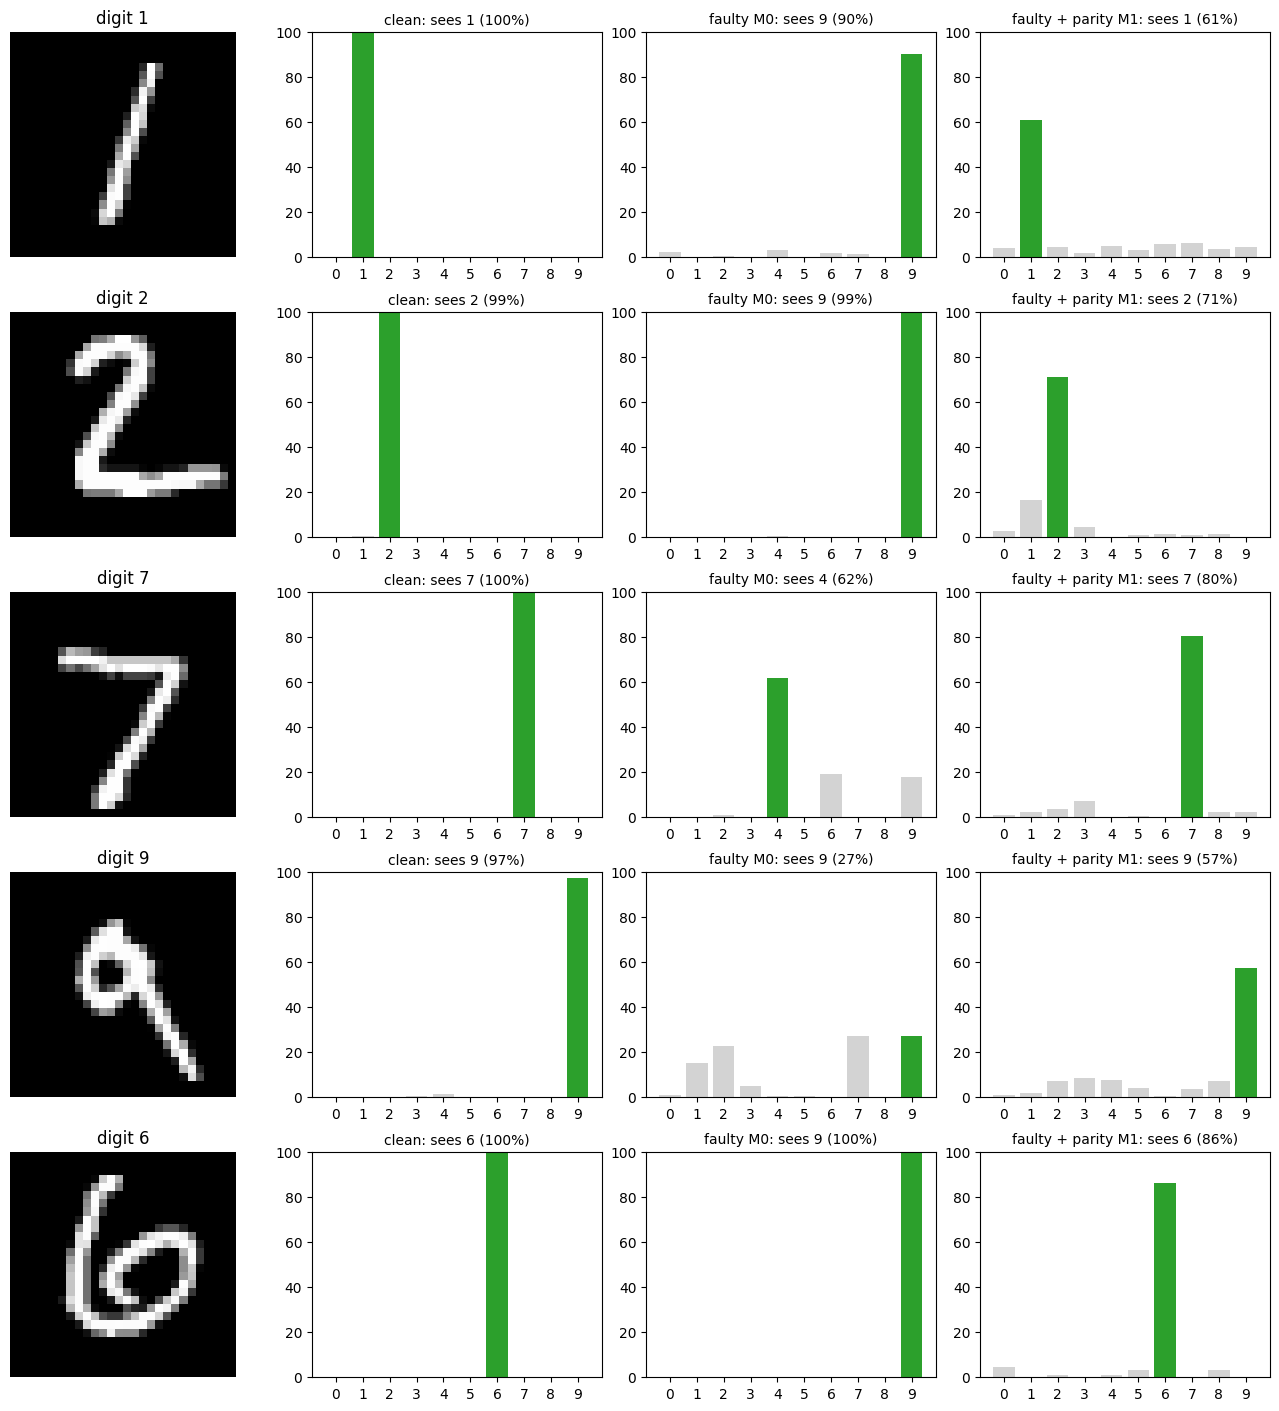


On all 10,000 test images: clean 97.98% | faulty 8.68% | faulty + parity 97.06%


In [ ]:
# ===== CODE 11b: fix cell for Code 11 (adds corrupt_all + checks your typed input) =====
# Run this AFTER Code 11 has been run once (it defines demo(), predict(), etc.), or any time later.
import copy
import torch


def corrupt_all(model, fmt, ber, seed, parity):
    """Random bit faults over ALL weights; parity=True -> parity-zero (odd number of flips -> weight read as 0)."""
    nb = NB[fmt]
    gen = torch.Generator().manual_seed(seed)
    m = copy.deepcopy(model)
    for lay in wlayers(m):
        q, s = quantize(lay.weight.data, fmt)
        flat = q.reshape(-1)
        hits = torch.rand(flat.numel(), nb + 1, generator=gen) < ber     # last column = parity bit
        mask = (hits[:, :nb].long() << torch.arange(nb)).sum(1)
        if fmt == "fp32":
            mask32 = torch.where(mask >= 2 ** 31, mask - 2 ** 32, mask).to(torch.int32)
            out = (flat.contiguous().view(torch.int32) ^ mask32).view(torch.float32)
        else:
            raw = (flat.to(torch.int64) & ((1 << nb) - 1)) ^ mask
            out = torch.where(raw >= (1 << (nb - 1)), raw - (1 << nb), raw).to(torch.int8)
        if parity:
            out = torch.where(hits.sum(1) % 2 == 1, torch.zeros_like(out), out)
        out = out.reshape(q.shape)
        lay.weight.data = out if fmt == "fp32" else out.float() * s
    return m


def num(prompt, default, cast):
    try:
        return cast(input(prompt).strip() or default)
    except ValueError:
        print(f"  not a valid number, using {default}")
        return cast(default)


def ask():
    raw = input("Digits to test, each ONE digit 0-9, separated by spaces (e.g. 3 4 5): ").split()
    digits = [int(d) for d in raw if len(d) == 1 and d.isdigit()]
    skipped = [d for d in raw if not (len(d) == 1 and d.isdigit())]
    if skipped:
        print("Skipped (the model only knows single digits 0-9):", skipped)
    if not digits:
        print("No valid digit given, please run again."); return
    fmt = (input("Format fp32 / int8 / int4 [int8]: ").strip() or "int8").lower()
    if fmt not in NB:
        print(f"'{fmt}' is not a format, using int8"); fmt = "int8"
    mode = (input("Fault type, type the word bit or ber  [bit]: ").strip() or "bit").lower()
    if mode not in ("bit", "ber"):
        print(f"'{mode}' is not bit or ber, using bit"); mode = "bit"
    if mode == "bit":
        layer = num("Layer 0=conv1 1=conv2 2=fc1 3=fc2 4=fc3 [4]: ", 4, int)
        frac = num("Fraction of that layer's weights flipped, e.g. 0.2 [0.2]: ", 0.2, float)
        demo(digits, fmt=fmt, mode="bit", layer=min(max(layer, 0), 4), frac=frac)
    else:
        ber = num("Bit error rate, e.g. 0.01 [0.01]: ", 0.01, float)
        demo(digits, fmt=fmt, mode="ber", ber=ber)


ask()

fp32 done
int8 done
int4 done
 fmt    ber            config  mean   std
fp32 0.0001           M0 none 20.06 14.57
fp32 0.0001    M1 parity-zero 97.93  0.10
fp32 0.0001 M4 weight nulling 97.99  0.04
fp32 0.0010           M0 none 10.75  4.17
fp32 0.0010    M1 parity-zero 58.67 37.73
fp32 0.0010 M4 weight nulling 97.77  0.25
fp32 0.0100           M0 none  9.80  0.00
fp32 0.0100    M1 parity-zero  9.80  0.00
fp32 0.0100 M4 weight nulling 95.51  1.65
int4 0.0001           M0 none 97.99  0.04
int4 0.0001    M1 parity-zero 98.00  0.03
int4 0.0001 M4 weight nulling 97.98  0.03
int4 0.0010           M0 none 97.64  0.33
int4 0.0010    M1 parity-zero 97.96  0.10
int4 0.0010 M4 weight nulling 97.71  0.24
int4 0.0100           M0 none 92.66  3.46
int4 0.0100    M1 parity-zero 97.42  0.39
int4 0.0100 M4 weight nulling 92.91  3.17
int8 0.0001           M0 none 97.99  0.07
int8 0.0001    M1 parity-zero 97.93  0.20
int8 0.0001 M4 weight nulling 97.98  0.07
int8 0.0010           M0 none 97.84  0.17
int8

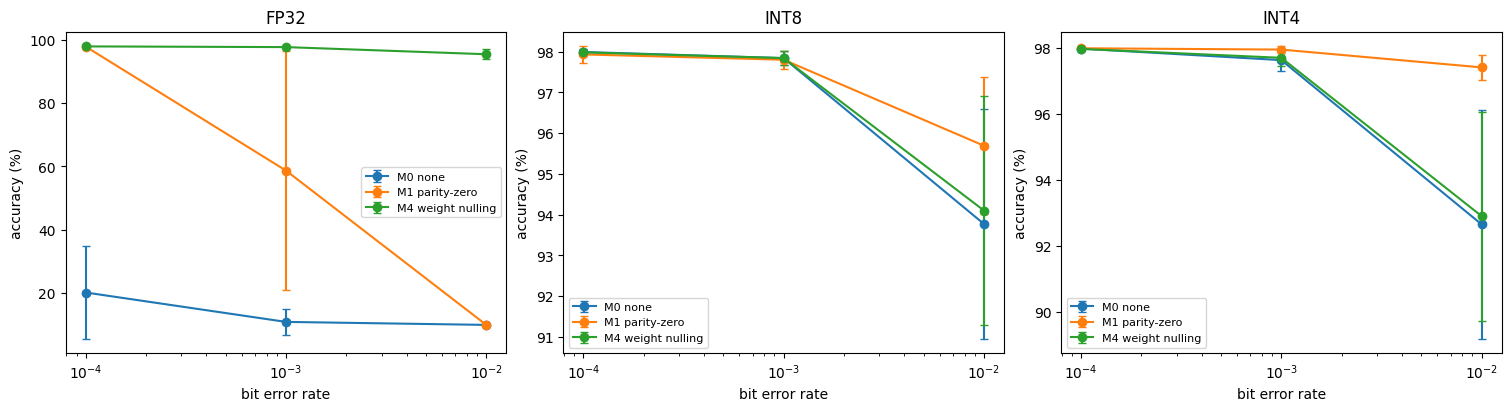

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ===== CODE 13: Weight Nulling (range check) - protection with NO extra storage per weight =====
# Idea: for each layer, remember ONE number: the largest |weight| of the clean model.
# At read time, any weight larger than that (or NaN/inf) cannot be genuine -> read it as 0.
# Cost: 1 float per layer + one comparator per weight read. Compared with M0 (nothing) and M1 (parity-zero).
# Needs Code 1 (cnn, acc, quantize, wlayers, NB, LAYER_NAMES).
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch


def corrupt_null(model, fmt, ber, seed, parity=False, null=False, margin=1.0):
    """Random bit faults on every stored bit (probability `ber`). Then optionally:
    parity=True : parity-zero (M1)        null=True : weight nulling by range check (M4)."""
    nb = NB[fmt]
    gen = torch.Generator().manual_seed(seed)
    m = copy.deepcopy(model)
    for lay in wlayers(m):
        q, s = quantize(lay.weight.data, fmt)
        flat = q.reshape(-1)
        hits = torch.rand(flat.numel(), nb + 1, generator=gen) < ber           # last column = parity bit
        mask = (hits[:, :nb].long() << torch.arange(nb)).sum(1)
        if fmt == "fp32":
            mask32 = torch.where(mask >= 2 ** 31, mask - 2 ** 32, mask).to(torch.int32)
            out = (flat.contiguous().view(torch.int32) ^ mask32).view(torch.float32)
        else:
            raw = (flat.to(torch.int64) & ((1 << nb) - 1)) ^ mask
            out = torch.where(raw >= (1 << (nb - 1)), raw - (1 << nb), raw).to(torch.int8)
        if parity:
            out = torch.where(hits.sum(1) % 2 == 1, torch.zeros_like(out), out)
        out = out.reshape(q.shape)
        w = out if fmt == "fp32" else out.float() * s
        if null:
            limit = lay.weight.data.abs().max() * margin                       # the ONE stored number per layer
            w = torch.where(w.abs() <= limit, w, torch.zeros_like(w))          # NaN/inf also fail this test
        lay.weight.data = w
    return m


BERS, SEEDS = [1e-4, 1e-3, 1e-2], range(10)
configs = {"M0 none": dict(), "M1 parity-zero": dict(parity=True), "M4 weight nulling": dict(null=True)}
rows = []
for fmt in NB:
    clean = acc(corrupt_null(cnn, fmt, 0.0, 0))
    for ber in BERS:
        for name, kw in configs.items():
            for seed in SEEDS:
                rows.append(dict(fmt=fmt, ber=ber, config=name, seed=seed, clean=clean,
                                 acc=acc(corrupt_null(cnn, fmt, ber, seed, **kw))))
    print(fmt, "done")
dfn = pd.DataFrame(rows)
dfn.to_csv("cnn_weight_nulling.csv", index=False)

pd.set_option("display.width", 200)
tab = dfn.groupby(["fmt", "ber", "config"]).acc.agg(["mean", "std"]).round(2).reset_index()
print(tab.to_string(index=False))
print("\nExtra storage: M1 parity = 100/bits % per weight (3.1 / 12.5 / 25); M4 nulling = 1 float per layer (about 0%).")

fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
for ax, fmt in zip(axes, NB):
    for name in configs:
        s = tab[(tab.fmt == fmt) & (tab.config == name)]
        ax.errorbar(s.ber, s["mean"], s["std"], marker="o", capsize=3, label=name)
    ax.set_xscale("log"); ax.set_xlabel("bit error rate"); ax.set_ylabel("accuracy (%)")
    ax.set_title(fmt.upper()); ax.legend(fontsize=8)
plt.savefig("cnn_weight_nulling.png", dpi=200, bbox_inches="tight")
plt.show()

from google.colab import files
files.download("cnn_weight_nulling.csv")
files.download("cnn_weight_nulling.png")

clip limits per layer: {'conv1': 2.64, 'conv2': 8.14, 'fc1': 18.99, 'fc2': 23.21, 'fc3': 20.83}
fp32 done
int8 done
int4 done
 fmt    ber           config  mean   std
fp32 0.0001          M0 none 20.06 14.57
fp32 0.0001          M1 + M5 97.93  0.10
fp32 0.0001   M1 parity-zero 97.93  0.10
fp32 0.0001 M5 act. clipping 82.15 23.81
fp32 0.0010          M0 none 10.75  4.17
fp32 0.0010          M1 + M5 90.79 16.33
fp32 0.0010   M1 parity-zero 58.67 37.73
fp32 0.0010 M5 act. clipping 29.73 13.98
fp32 0.0100          M0 none  9.80  0.00
fp32 0.0100          M1 + M5 11.91  4.74
fp32 0.0100   M1 parity-zero  9.80  0.00
fp32 0.0100 M5 act. clipping 10.00  0.84
int4 0.0001          M0 none 97.99  0.04
int4 0.0001          M1 + M5 98.00  0.03
int4 0.0001   M1 parity-zero 98.00  0.03
int4 0.0001 M5 act. clipping 97.99  0.04
int4 0.0010          M0 none 97.64  0.33
int4 0.0010          M1 + M5 97.96  0.10
int4 0.0010   M1 parity-zero 97.96  0.10
int4 0.0010 M5 act. clipping 97.64  0.33
int4 0.0100  

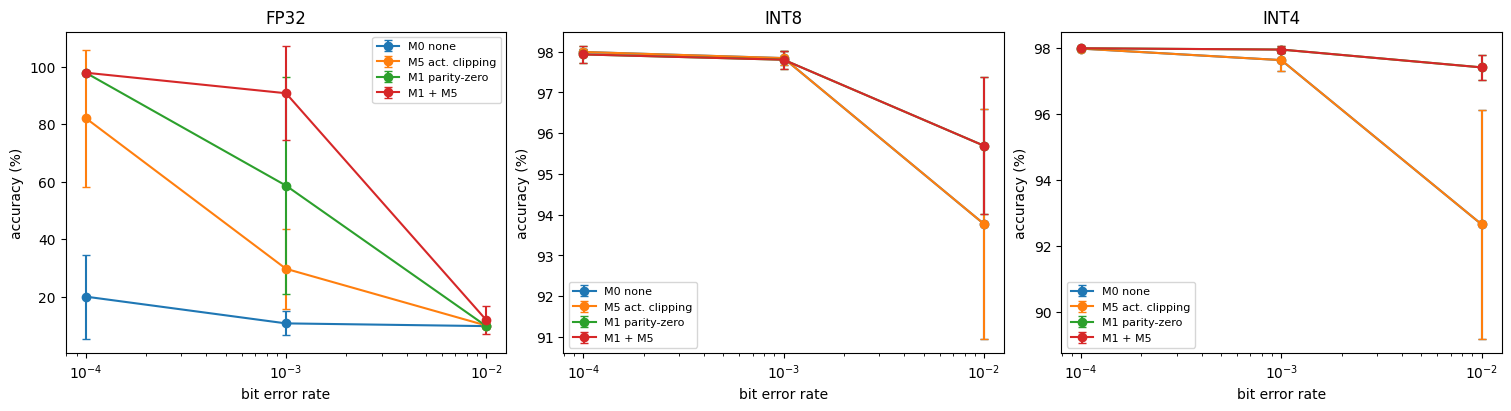

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ===== CODE 14: Activation clipping (Ranger-style) - clip every layer's output to the range seen on clean data =====
# Idea: run the CLEAN model on 2,000 training images and remember the largest |output| of each weight layer.
# At run time every layer output is clipped to that range (NaN -> 0, +-inf -> the limit).
# No extra storage per weight; cost = one clamp per activation. Needs Code 1 and Code 13 (corrupt_null).
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

# 1) calibration: largest |output| of each Conv/Linear layer on clean data
bounds, hooks = {}, []
for i, lay in enumerate(wlayers(cnn)):
    hooks.append(lay.register_forward_hook(
        lambda mod, inp, out, i=i: bounds.__setitem__(i, max(bounds.get(i, 0.0), float(out.abs().max())))))
with torch.no_grad():
    cnn(Xtr[:2000])
for h in hooks:
    h.remove()
print("clip limits per layer:", {LAYER_NAMES[i]: round(b, 2) for i, b in bounds.items()})


def add_clipping(model, margin=1.1):
    """Attach a clamp to the output of every Conv/Linear layer of `model` (in place)."""
    for i, lay in enumerate(wlayers(model)):
        b = bounds[i] * margin
        lay.register_forward_hook(
            lambda mod, inp, out, b=b: torch.nan_to_num(out, nan=0.0, posinf=b, neginf=-b).clamp(-b, b))
    return model


BERS, SEEDS = [1e-4, 1e-3, 1e-2], range(10)
configs = {"M0 none": dict(clip=False), "M5 act. clipping": dict(clip=True),
           "M1 parity-zero": dict(clip=False, parity=True), "M1 + M5": dict(clip=True, parity=True)}
rows = []
for fmt in NB:
    clean = acc(corrupt_null(cnn, fmt, 0.0, 0))
    for ber in BERS:
        for name, kw in configs.items():
            for seed in SEEDS:
                kw2 = dict(kw); clip = kw2.pop("clip")
                m = corrupt_null(cnn, fmt, ber, seed, **kw2)
                if clip:
                    add_clipping(m)
                rows.append(dict(fmt=fmt, ber=ber, config=name, seed=seed, clean=clean, acc=acc(m)))
    print(fmt, "done")
dfc = pd.DataFrame(rows)
dfc.to_csv("cnn_activation_clipping.csv", index=False)

pd.set_option("display.width", 200)
tab = dfc.groupby(["fmt", "ber", "config"]).acc.agg(["mean", "std"]).round(2).reset_index()
print(tab.to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
for ax, fmt in zip(axes, NB):
    for name in configs:
        s = tab[(tab.fmt == fmt) & (tab.config == name)]
        ax.errorbar(s.ber, s["mean"], s["std"], marker="o", capsize=3, label=name)
    ax.set_xscale("log"); ax.set_xlabel("bit error rate"); ax.set_ylabel("accuracy (%)")
    ax.set_title(fmt.upper()); ax.legend(fontsize=8)
plt.savefig("cnn_activation_clipping.png", dpi=200, bbox_inches="tight")
plt.show()

from google.colab import files
files.download("cnn_activation_clipping.csv")
files.download("cnn_activation_clipping.png")

In [ ]:
# ===== CODE 15 (self-contained): M1 + M4 together - parity-zero AND weight nulling, FP32 only =====
# Needs only Code 1 (cnn, acc, quantize, wlayers, NB). Parity catches single flips; nulling catches huge values.
import copy
import numpy as np
import pandas as pd
import torch


def corrupt_null(model, fmt, ber, seed, parity=False, null=False, margin=1.0):
    """Random bit faults on every stored bit (probability `ber`). Then optionally:
    parity=True : parity-zero (M1)        null=True : weight nulling by range check (M4)."""
    nb = NB[fmt]
    gen = torch.Generator().manual_seed(seed)
    m = copy.deepcopy(model)
    for lay in wlayers(m):
        q, s = quantize(lay.weight.data, fmt)
        flat = q.reshape(-1)
        hits = torch.rand(flat.numel(), nb + 1, generator=gen) < ber           # last column = parity bit
        mask = (hits[:, :nb].long() << torch.arange(nb)).sum(1)
        if fmt == "fp32":
            mask32 = torch.where(mask >= 2 ** 31, mask - 2 ** 32, mask).to(torch.int32)
            out = (flat.contiguous().view(torch.int32) ^ mask32).view(torch.float32)
        else:
            raw = (flat.to(torch.int64) & ((1 << nb) - 1)) ^ mask
            out = torch.where(raw >= (1 << (nb - 1)), raw - (1 << nb), raw).to(torch.int8)
        if parity:
            out = torch.where(hits.sum(1) % 2 == 1, torch.zeros_like(out), out)
        out = out.reshape(q.shape)
        w = out if fmt == "fp32" else out.float() * s
        if null:
            limit = lay.weight.data.abs().max() * margin                       # the ONE stored number per layer
            w = torch.where(w.abs() <= limit, w, torch.zeros_like(w))          # NaN/inf also fail this test
        lay.weight.data = w
    return m


rows = []
for ber in [1e-4, 1e-3, 1e-2]:
    for name, kw in {"M4 weight nulling": dict(null=True),
                     "M1 + M4": dict(parity=True, null=True)}.items():
        for seed in range(10):
            rows.append(dict(fmt="fp32", ber=ber, config=name, seed=seed,
                             acc=acc(corrupt_null(cnn, "fp32", ber, seed, **kw))))
d = pd.DataFrame(rows)
d.to_csv("cnn_m1_plus_m4_fp32.csv", index=False)


def boot(x, n=4000):
    x = np.asarray(x); r = np.random.default_rng(0)
    m = x[r.integers(0, len(x), (n, len(x)))].mean(1)
    return round(np.percentile(m, 2.5), 2), round(np.percentile(m, 97.5), 2)


out = []
for (ber, c), g in d.groupby(["ber", "config"], sort=False):
    lo, hi = boot(g.acc)
    out.append(dict(ber=ber, config=c, mean=round(g.acc.mean(), 2), std=round(g.acc.std(), 2), ci_low=lo, ci_high=hi))
print(pd.DataFrame(out).to_string(index=False))
print("\nExtra storage: M4 = about 0 (1 float per layer); M1 + M4 = 3.1% (one parity bit per 32-bit weight).")

from google.colab import files
files.download("cnn_m1_plus_m4_fp32.csv")

   ber            config  mean  std  ci_low  ci_high
0.0001 M4 weight nulling 97.99 0.04   97.97    98.02
0.0001           M1 + M4 97.93 0.10   97.87    98.00
0.0010 M4 weight nulling 97.77 0.25   97.61    97.89
0.0010           M1 + M4 97.57 0.43   97.29    97.79
0.0100 M4 weight nulling 95.51 1.65   94.48    96.42
0.0100           M1 + M4 89.11 3.97   86.74    91.39

Extra storage: M4 = about 0 (1 float per layer); M1 + M4 = 3.1% (one parity bit per 32-bit weight).


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

fp32 done
int8 done
int4 done

First flips chosen by the greedy attacker (layer, weight index, bit, old -> new value):

FP32 greedy
 step layer  index  bit     old           new
    1 conv1     81   30  0.3040  1.034000e+38
    2   fc1  36824   26 -0.0067 -1.720000e+00
    3   fc1  16372   25 -0.0534 -8.544000e-01
    4   fc1    402    0 -0.0170 -1.705000e-02
    5   fc1    402    0 -0.0170 -1.705000e-02
    6   fc1    402    0 -0.0170 -1.705000e-02

FP32 greedy range-aware
 step layer  index  bit     old     new
    1   fc3    756   31  0.1441 -0.1441
    2 conv1    113   31  0.3443 -0.3443
    3 conv1    142   31  0.3896 -0.3896
    4 conv1    141   31  0.3064 -0.3064
    5 conv1    139   31  0.2794 -0.2794
    6 conv1     83   31 -0.2596  0.2596

INT8 greedy
 step layer  index  bit    old     new
    1   fc3    756    7 0.1442 -0.1976
    2   fc3    758    7 0.1041 -0.2377
    3   fc3    779    7 0.1442 -0.1976
    4   fc3    838    7 0.0801 -0.2617
    5   fc3    817    7 0.1469 -0

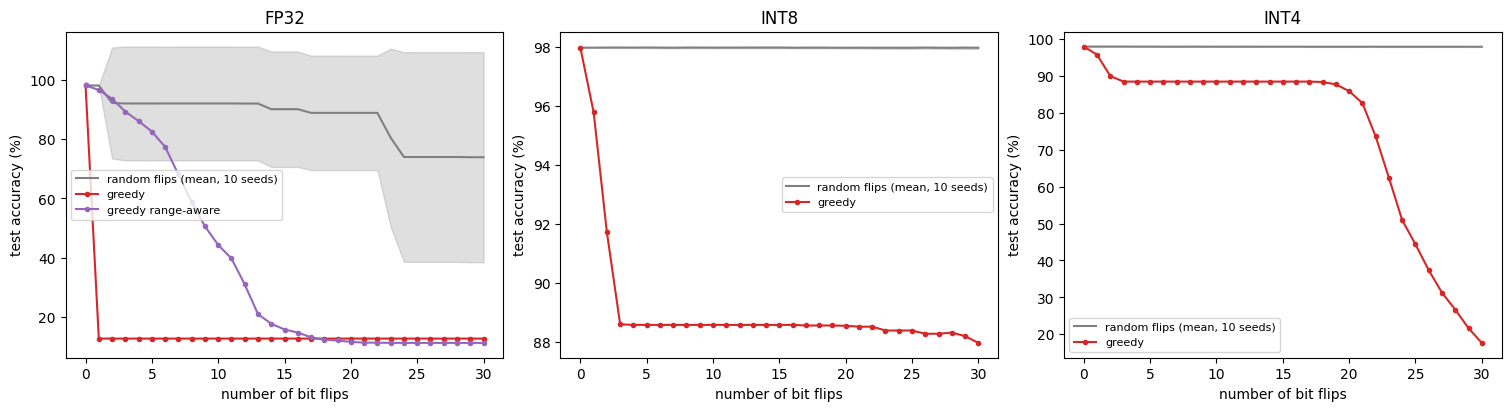

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ===== CODE 16: the ATTACKER - greedy bit search vs random flips =====
# Random faults flip bits blindly. An attacker picks the few bits that hurt the most (gradient-guided greedy search,
# in the spirit of the Bit-Flip Attack). We measure: how many flips until the model breaks?
#   greedy        : best bit anywhere in the network, one flip at a time (unprotected model)
#   greedy, range-aware (FP32 only): the attacker knows about weight nulling and only uses flips whose
#                   new value stays inside the layer's clean range, so the range check cannot see them
#   random        : same number of flips at random positions (10 seeds), for comparison
# Needs Code 1 (cnn, acc, quantize, wlayers, NB, LAYER_NAMES, Xtr, Ytr).
import copy
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

ATT_X, ATT_Y = Xtr[:500], Ytr[:500]                    # the attacker sees 500 TRAINING images, never the test set
LIMITS = [lay.weight.data.abs().max().item() for lay in wlayers(cnn)]
STEPS = 30


def all_flips(q, fmt, scale):
    """Every single-bit flip of every stored value of one layer.
    Returns (new stored values, new dequantized values), each of shape (bits, number of weights)."""
    nb = NB[fmt]
    flat = q.reshape(-1)
    if fmt == "fp32":
        masks = torch.tensor([1 << b for b in range(31)] + [-2 ** 31], dtype=torch.int32)
        newq = (flat.contiguous().view(torch.int32)[None, :] ^ masks[:, None]).view(torch.float32)
        return newq, newq
    raw = (flat.to(torch.int64) & ((1 << nb) - 1))[None, :] ^ (1 << torch.arange(nb))[:, None]
    newq = torch.where(raw >= (1 << (nb - 1)), raw - (1 << nb), raw)
    return newq, newq.float() * scale


def stored_model(fmt):
    m = copy.deepcopy(cnn)
    qs, scales = [], []
    for lay in wlayers(m):
        q, s = quantize(lay.weight.data, fmt)
        qs.append(q.clone()); scales.append(s)
        lay.weight.data = q.clone() if fmt == "fp32" else q.float() * s
    return m, qs, scales


def greedy_attack(fmt, steps=STEPS, topk=5, range_aware=False):
    m, qs, scales = stored_model(fmt)
    layers = wlayers(m)
    curve, log = [acc(m)], []
    for step in range(steps):
        for lay in layers:
            lay.weight.grad = None
            lay.weight.requires_grad_(True)
        F.cross_entropy(m(ATT_X), ATT_Y).backward()               # how does the loss change with each weight?
        grads = [lay.weight.grad.reshape(-1).clone() for lay in layers]
        for lay in layers:
            lay.weight.requires_grad_(False)
        cands = []
        for li, lay in enumerate(layers):
            old = lay.weight.data.reshape(-1)
            newq, newv = all_flips(qs[li], fmt, scales[li])
            score = torch.nan_to_num(grads[li][None, :] * (newv - old[None, :]), nan=-1e30, posinf=1e30, neginf=-1e30)
            if range_aware:                                       # only flips that stay inside the clean range
                ok = torch.isfinite(newv) & (newv.abs() <= LIMITS[li])
                score = torch.where(ok, score, torch.full_like(score, -1e30))
            flat_score = score.reshape(-1)
            for t in torch.topk(flat_score, topk).indices.tolist():
                if flat_score[t] <= -1e29:
                    continue
                b, i = divmod(t, old.numel())
                cands.append((li, i, b, newq[b, i].clone(), float(newv[b, i])))
        if not cands:
            break
        best, best_loss = None, -1.0
        for li, i, b, nq, nv in cands:                            # check the real loss of each shortlisted flip
            w = layers[li].weight.data.reshape(-1)
            keep = w[i].item()
            w[i] = nv
            with torch.no_grad():
                l = F.cross_entropy(m(ATT_X), ATT_Y).item()
            w[i] = keep
            l = float("inf") if l != l else l
            if l > best_loss:
                best, best_loss = (li, i, b, nq, nv), l
        li, i, b, nq, nv = best
        old_val = layers[li].weight.data.reshape(-1)[i].item()
        qs[li].reshape(-1)[i] = nq
        layers[li].weight.data.reshape(-1)[i] = nv
        log.append(dict(step=step + 1, layer=LAYER_NAMES[li], index=i, bit=b, old=round(old_val, 4), new=float(f"{nv:.4g}")))
        curve.append(acc(m))
    return curve, log


def random_attack(fmt, seed, steps=STEPS):
    gen = torch.Generator().manual_seed(seed)
    m, qs, scales = stored_model(fmt)
    layers = wlayers(m)
    sizes = torch.tensor([q.numel() for q in qs], dtype=torch.float)
    curve = [acc(m)]
    for _ in range(steps):
        li = int(torch.multinomial(sizes, 1, generator=gen))      # every stored bit equally likely
        i = int(torch.randint(qs[li].numel(), (1,), generator=gen))
        b = int(torch.randint(NB[fmt], (1,), generator=gen))
        newq, newv = all_flips(qs[li].reshape(-1)[i:i + 1], fmt, scales[li])
        qs[li].reshape(-1)[i] = newq[b, 0]
        layers[li].weight.data.reshape(-1)[i] = newv[b, 0]
        curve.append(acc(m))
    return curve


rows, logs = [], {}
for fmt in NB:
    curve, logs[(fmt, "greedy")] = greedy_attack(fmt)
    rows += [dict(fmt=fmt, attack="greedy", seed=0, flips=k, acc=a) for k, a in enumerate(curve)]
    if fmt == "fp32":
        curve, logs[(fmt, "greedy range-aware")] = greedy_attack(fmt, range_aware=True)
        rows += [dict(fmt=fmt, attack="greedy range-aware", seed=0, flips=k, acc=a) for k, a in enumerate(curve)]
    for seed in range(10):
        curve = random_attack(fmt, seed)
        rows += [dict(fmt=fmt, attack="random", seed=seed, flips=k, acc=a) for k, a in enumerate(curve)]
    print(fmt, "done")
atk = pd.DataFrame(rows)
atk.to_csv("cnn_attack_curves.csv", index=False)

pd.set_option("display.width", 200)
print("\nFirst flips chosen by the greedy attacker (layer, weight index, bit, old -> new value):")
for (fmt, kind), log in logs.items():
    print(f"\n{fmt.upper()} {kind}")
    print(pd.DataFrame(log[:6]).to_string(index=False))


def flips_to_reach(curve, level):
    below = [k for k, a in enumerate(curve) if a < level]
    return below[0] if below else f">{len(curve) - 1}"


summary = []
for (fmt, kind), g in atk[atk.attack != "random"].groupby(["fmt", "attack"]):
    c = g.sort_values("flips").acc.tolist()
    summary.append(dict(fmt=fmt, attack=kind, clean=round(c[0], 2), flips_to_below_90=flips_to_reach(c, 90),
                        flips_to_below_50=flips_to_reach(c, 50), acc_after_10=round(c[min(10, len(c) - 1)], 2),
                        acc_after_30=round(c[-1], 2)))
for fmt, g in atk[atk.attack == "random"].groupby("fmt"):
    mean = g.groupby("flips").acc.mean()
    summary.append(dict(fmt=fmt, attack="random (mean of 10 seeds)", clean=round(mean.iloc[0], 2),
                        flips_to_below_90=flips_to_reach(mean.tolist(), 90), flips_to_below_50=flips_to_reach(mean.tolist(), 50),
                        acc_after_10=round(mean.loc[10], 2), acc_after_30=round(mean.iloc[-1], 2)))
print("\n", pd.DataFrame(summary).to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
for ax, fmt in zip(axes, NB):
    g = atk[atk.fmt == fmt]
    r = g[g.attack == "random"].groupby("flips").acc.agg(["mean", "std"])
    ax.plot(r.index, r["mean"], color="gray", label="random flips (mean, 10 seeds)")
    ax.fill_between(r.index, r["mean"] - r["std"], r["mean"] + r["std"], color="gray", alpha=0.25)
    for kind, c in [("greedy", "tab:red"), ("greedy range-aware", "tab:purple")]:
        s = g[g.attack == kind].sort_values("flips")
        if len(s):
            ax.plot(s.flips, s.acc, marker="o", ms=3, color=c, label=kind)
    ax.set_xlabel("number of bit flips"); ax.set_ylabel("test accuracy (%)"); ax.set_title(fmt.upper())
    ax.legend(fontsize=8)
plt.savefig("cnn_attack_curves.png", dpi=200, bbox_inches="tight")
plt.show()

from google.colab import files
files.download("cnn_attack_curves.csv")
files.download("cnn_attack_curves.png")

fp32 done
int8 done
int4 done
 fmt   ber            config  accuracy  broken_pct  conf_when_right  conf_when_wrong  wrong_and_sure_pct
fp32 0.001           M0 none      8.28       65.18        32.000000        78.000000               21.14
fp32 0.001    M1 parity-zero     50.84        0.00        97.500000        99.199997               48.12
fp32 0.001 M4 weight nulling     97.71        0.00        98.199997        70.699997                0.45
fp32 0.010           M0 none      9.80      100.00        10.000000              NaN                0.00
fp32 0.010    M1 parity-zero      9.80      100.00        10.000000              NaN                0.00
fp32 0.010 M4 weight nulling     96.50        0.00        94.099998        59.799999                0.21
int8 0.001           M0 none     97.81        0.00        98.400002        72.300003                0.47
int8 0.001    M1 parity-zero     97.76        0.00        98.199997        70.599998                0.46
int8 0.001 M4 weight null

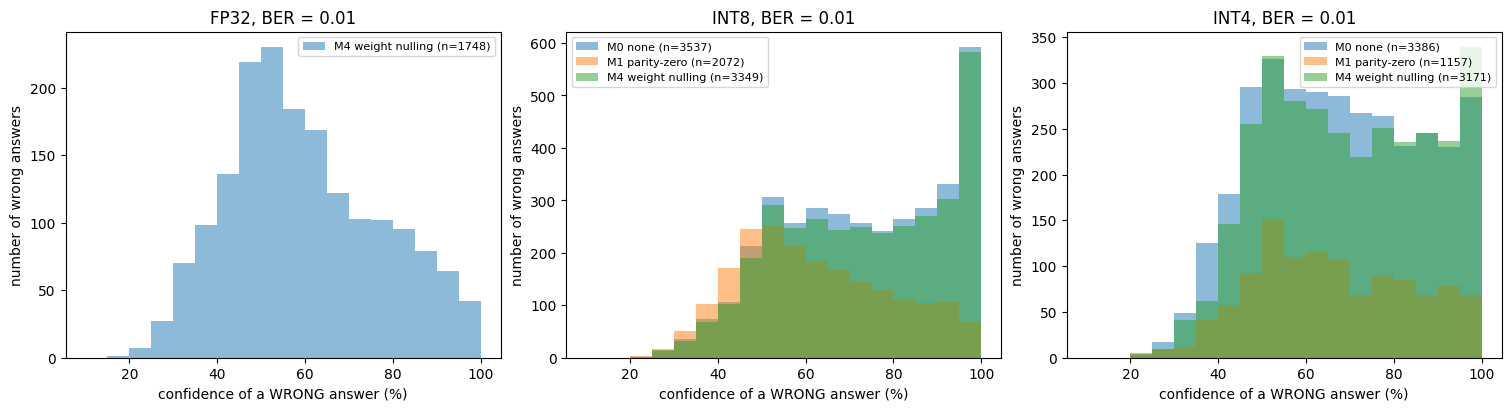

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ===== CODE 17: confidence analysis - when the faulty model is wrong, how SURE is it? =====
# A model that is wrong but unsure is easy to catch; a model that is wrong and very sure is dangerous.
# Needs only Code 1 (cnn, Xte, Yte, quantize, wlayers, NB). Self-contained otherwise.
import copy
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt


def corrupt_null(model, fmt, ber, seed, parity=False, null=False, margin=1.0):
    """Random bit faults on every stored bit; optional parity-zero (M1) and weight nulling (M4)."""
    nb = NB[fmt]
    gen = torch.Generator().manual_seed(seed)
    m = copy.deepcopy(model)
    for lay in wlayers(m):
        q, s = quantize(lay.weight.data, fmt)
        flat = q.reshape(-1)
        hits = torch.rand(flat.numel(), nb + 1, generator=gen) < ber
        mask = (hits[:, :nb].long() << torch.arange(nb)).sum(1)
        if fmt == "fp32":
            mask32 = torch.where(mask >= 2 ** 31, mask - 2 ** 32, mask).to(torch.int32)
            out = (flat.contiguous().view(torch.int32) ^ mask32).view(torch.float32)
        else:
            raw = (flat.to(torch.int64) & ((1 << nb) - 1)) ^ mask
            out = torch.where(raw >= (1 << (nb - 1)), raw - (1 << nb), raw).to(torch.int8)
        if parity:
            out = torch.where(hits.sum(1) % 2 == 1, torch.zeros_like(out), out)
        out = out.reshape(q.shape)
        w = out if fmt == "fp32" else out.float() * s
        if null:
            limit = lay.weight.data.abs().max() * margin
            w = torch.where(w.abs() <= limit, w, torch.zeros_like(w))
        lay.weight.data = w
    return m


def analyse(m):
    """Per-image results: broken (output is NaN), correct, confidence of the chosen digit (%)."""
    with torch.no_grad():
        logits = m(Xte)
    broken = torch.isnan(logits).any(1)
    probs = torch.softmax(torch.nan_to_num(logits, nan=0.0, posinf=1e30, neginf=-1e30), 1)
    conf, pred = probs.max(1)
    return broken.numpy(), (pred == Yte).numpy(), (conf * 100).numpy()


CONFIGS = {"M0 none": dict(), "M1 parity-zero": dict(parity=True), "M4 weight nulling": dict(null=True)}
BERS, SEEDS = [1e-3, 1e-2], range(5)
rows, wrong_conf = [], {}
for fmt in NB:
    for ber in BERS:
        for name, kw in CONFIGS.items():
            B, C, P = [], [], []
            for seed in SEEDS:
                b, c, p = analyse(corrupt_null(cnn, fmt, ber, seed, **kw))
                B.append(b); C.append(c); P.append(p)
            B, C, P = map(np.concatenate, (B, C, P))
            wrong = ~C & ~B                                    # wrong answer from a model that still produced numbers
            wrong_conf[(fmt, ber, name)] = P[wrong]
            rows.append(dict(fmt=fmt, ber=ber, config=name,
                             accuracy=round(100 * C.mean(), 2),
                             broken_pct=round(100 * B.mean(), 2),
                             conf_when_right=round(P[C].mean(), 1) if C.any() else np.nan,
                             conf_when_wrong=round(P[wrong].mean(), 1) if wrong.any() else np.nan,
                             wrong_and_sure_pct=round(100 * (P[wrong] >= 90).sum() / len(P), 2)))
    print(fmt, "done")
res = pd.DataFrame(rows)
res.to_csv("cnn_confidence.csv", index=False)
pd.set_option("display.width", 220)
print(res.to_string(index=False))
print("\nbroken_pct = images where the output was NaN (model destroyed, easy to notice).")
print("wrong_and_sure_pct = share of ALL predictions that are wrong while the model is at least 90% confident.")

fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
for ax, fmt in zip(axes, NB):
    for name in CONFIGS:
        v = wrong_conf[(fmt, 1e-2, name)]
        if len(v):
            ax.hist(v, bins=np.linspace(10, 100, 19), alpha=0.5, label=f"{name} (n={len(v)})")
    ax.set_xlabel("confidence of a WRONG answer (%)"); ax.set_ylabel("number of wrong answers")
    ax.set_title(f"{fmt.upper()}, BER = 0.01"); ax.legend(fontsize=8)
plt.savefig("cnn_confidence.png", dpi=200, bbox_inches="tight")
plt.show()

from google.colab import files
files.download("cnn_confidence.csv")
files.download("cnn_confidence.png")

100%|██████████| 26.4M/26.4M [00:01<00:00, 17.3MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 286kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 4.76MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 20.1MB/s]


Fashion-MNIST clean accuracy: {'fp32': 87.24, 'int8': 87.12, 'int4': 82.05}
sweep fp32 done
sweep int8 done
sweep int4 done

Most harmful bits per format (mean drop, points):
  fp32: bit 30: 61.27, bit 25: 11.32, bit 26: 1.96
  int8: bit 7: 5.0, bit 6: 0.9, bit 5: 0.09
  int4: bit 3: 5.74, bit 2: 1.41, bit 1: 0.37


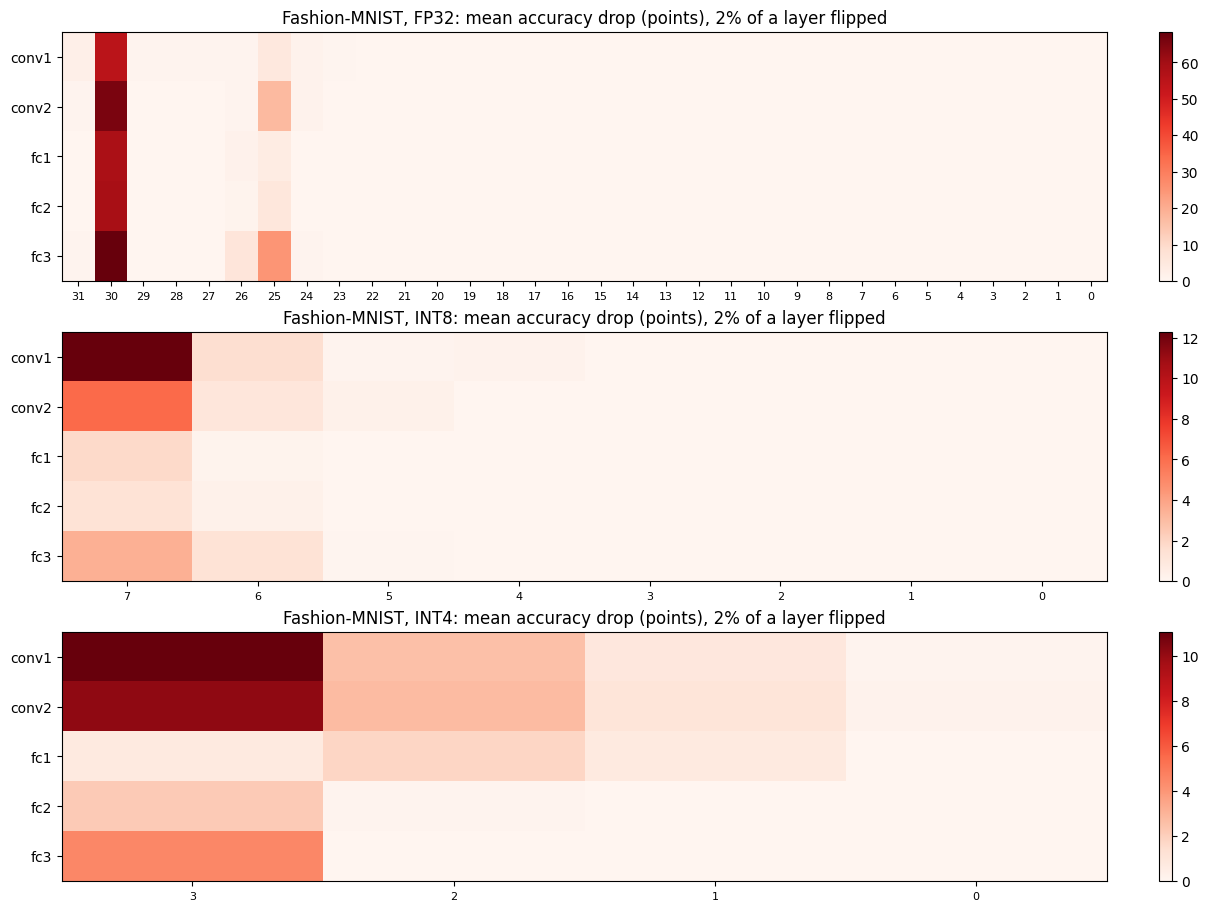

ber fp32 done
ber int8 done
ber int4 done
 fmt    ber            config  mean   std
fp32 0.0001           M0 none 22.46 24.83
fp32 0.0001    M1 parity-zero 86.60  1.15
fp32 0.0001 M4 weight nulling 87.00  0.40
fp32 0.0010           M0 none  9.09  1.97
fp32 0.0010    M1 parity-zero 59.64 32.12
fp32 0.0010 M4 weight nulling 86.27  1.19
fp32 0.0100           M0 none 10.00  0.00
fp32 0.0100    M1 parity-zero 10.00  0.00
fp32 0.0100 M4 weight nulling 78.09  5.03
int4 0.0001           M0 none 81.88  0.61
int4 0.0001    M1 parity-zero 82.00  0.09
int4 0.0001 M4 weight nulling 81.93  0.55
int4 0.0010           M0 none 81.38  1.38
int4 0.0010    M1 parity-zero 81.85  0.82
int4 0.0010 M4 weight nulling 81.78  1.42
int4 0.0100           M0 none 66.01  7.96
int4 0.0100    M1 parity-zero 78.21  2.16
int4 0.0100 M4 weight nulling 65.01  8.10
int8 0.0001           M0 none 87.09  0.24
int8 0.0001    M1 parity-zero 87.20  0.04
int8 0.0001 M4 weight nulling 87.09  0.24
int8 0.0010           M0 none 86.5

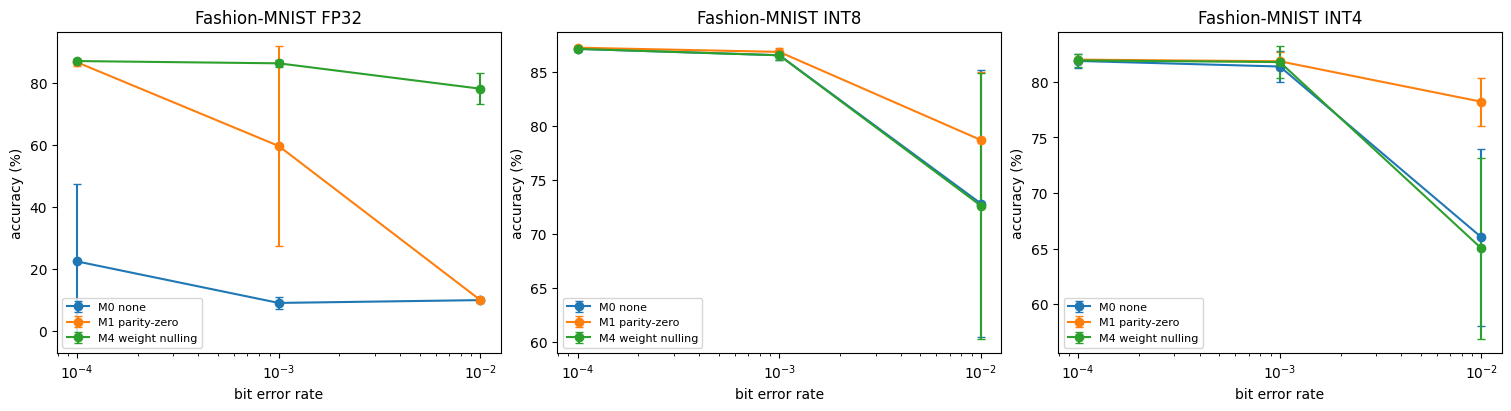

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ===== CODE 18: second dataset - Fashion-MNIST (same CNN, same experiments, own variable names) =====
# Self-contained: it does NOT touch your MNIST model (everything starts with f / F). Takes ~15-25 minutes.
import copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torchvision import datasets

# ---------- data (Fashion-MNIST downloads automatically) ----------
_tr = datasets.FashionMNIST("data", train=True, download=True)
_te = datasets.FashionMNIST("data", train=False, download=True)
FXtr, FYtr = (_tr.data.float() / 255).unsqueeze(1), _tr.targets
FXte, FYte = (_te.data.float() / 255).unsqueeze(1), _te.targets
# ---------- end data ----------

FNB = {"fp32": 32, "int8": 8, "int4": 4}
FNAMES = ["conv1", "conv2", "fc1", "fc2", "fc3"]
torch.manual_seed(0)
fcnn = nn.Sequential(
    nn.Conv2d(1, 6, 5, padding=2), nn.ReLU(), nn.MaxPool2d(2),
    nn.Conv2d(6, 16, 5), nn.ReLU(), nn.MaxPool2d(2),
    nn.Flatten(),
    nn.Linear(400, 120), nn.ReLU(),
    nn.Linear(120, 84), nn.ReLU(),
    nn.Linear(84, 10),
)
opt = torch.optim.Adam(fcnn.parameters(), lr=1e-3)
g_train = torch.Generator().manual_seed(0)
for epoch in range(4):
    perm = torch.randperm(len(FXtr), generator=g_train)
    for i in range(0, len(FXtr), 128):
        idx = perm[i:i + 128]
        opt.zero_grad()
        nn.functional.cross_entropy(fcnn(FXtr[idx]), FYtr[idx]).backward()
        opt.step()


def facc(m):
    with torch.no_grad():
        return 100 * (m(FXte).argmax(1) == FYte).float().mean().item()


def fwl(m):
    return [x for x in m.modules() if isinstance(x, (nn.Conv2d, nn.Linear))]


def fquant(w, fmt):
    if fmt == "fp32":
        return w.clone(), torch.tensor(1.0)
    qmax = 2 ** (FNB[fmt] - 1) - 1
    scale = w.abs().max() / qmax
    return torch.clamp(torch.round(w / scale), -(qmax + 1), qmax).to(torch.int8), scale


def fflip(q, fmt, bit, frac, gen):
    flat = q.reshape(-1)
    idx = torch.randperm(flat.numel(), generator=gen)[:int(frac * flat.numel())]
    masks = torch.zeros(flat.numel(), dtype=torch.int64)
    masks[idx] = 1 << bit
    if fmt == "fp32":
        out = (flat.contiguous().view(torch.int32) ^ masks.to(torch.int32)).view(torch.float32)
    else:
        nb = FNB[fmt]
        raw = (flat.to(torch.int64) & ((1 << nb) - 1)) ^ masks
        out = torch.where(raw >= (1 << (nb - 1)), raw - (1 << nb), raw).to(torch.int8)
    return out.reshape(q.shape)


def fbuild(model, fmt, layer=None, bit=None, frac=0.02, gen=None):
    m = copy.deepcopy(model)
    for li, lay in enumerate(fwl(m)):
        q, s = fquant(lay.weight.data, fmt)
        if li == layer:
            q = fflip(q, fmt, bit, frac, gen)
        lay.weight.data = q if fmt == "fp32" else q.float() * s
    return m


def fcorrupt(model, fmt, ber, seed, parity=False, null=False):
    nb = FNB[fmt]
    gen = torch.Generator().manual_seed(seed)
    m = copy.deepcopy(model)
    for lay in fwl(m):
        q, s = fquant(lay.weight.data, fmt)
        flat = q.reshape(-1)
        hits = torch.rand(flat.numel(), nb + 1, generator=gen) < ber
        mask = (hits[:, :nb].long() << torch.arange(nb)).sum(1)
        if fmt == "fp32":
            mask32 = torch.where(mask >= 2 ** 31, mask - 2 ** 32, mask).to(torch.int32)
            out = (flat.contiguous().view(torch.int32) ^ mask32).view(torch.float32)
        else:
            raw = (flat.to(torch.int64) & ((1 << nb) - 1)) ^ mask
            out = torch.where(raw >= (1 << (nb - 1)), raw - (1 << nb), raw).to(torch.int8)
        if parity:
            out = torch.where(hits.sum(1) % 2 == 1, torch.zeros_like(out), out)
        out = out.reshape(q.shape)
        w = out if fmt == "fp32" else out.float() * s
        if null:
            w = torch.where(w.abs() <= lay.weight.data.abs().max(), w, torch.zeros_like(w))
        lay.weight.data = w
    return m


print("Fashion-MNIST clean accuracy:", {f: round(facc(fbuild(fcnn, f)), 2) for f in FNB})

# ---- A) layer x bit sweep (2% of a layer's weights, 5 seeds) ----
rows = []
for fmt, nbits in FNB.items():
    clean = facc(fbuild(fcnn, fmt))
    for layer in range(5):
        for bit in range(nbits):
            for seed in range(5):
                a = facc(fbuild(fcnn, fmt, layer, bit, 0.02, torch.Generator().manual_seed(seed)))
                rows.append(dict(fmt=fmt, layer=layer, bit=bit, seed=seed, clean_acc=clean, acc=a, drop=clean - a))
    print("sweep", fmt, "done")
fs = pd.DataFrame(rows)
fs.to_csv("fashion_bit_sweep.csv", index=False)
print("\nMost harmful bits per format (mean drop, points):")
for fmt in FNB:
    t = fs[fs.fmt == fmt].groupby("bit").drop.mean().sort_values(ascending=False).head(3).round(2)
    print(f"  {fmt}: " + ", ".join(f"bit {b}: {v}" for b, v in t.items()))

fig, axes = plt.subplots(3, 1, figsize=(12, 9), constrained_layout=True)
for ax, fmt in zip(axes, FNB):
    t = fs[fs.fmt == fmt].pivot_table(index="layer", columns="bit", values="drop", aggfunc="mean")
    t = t[sorted(t.columns, reverse=True)]
    im = ax.imshow(t.values, cmap="Reds", aspect="auto", vmin=0, vmax=max(t.values.max(), 1.0))
    ax.set_xticks(range(t.shape[1])); ax.set_xticklabels(t.columns, fontsize=8)
    ax.set_yticks(range(5)); ax.set_yticklabels(FNAMES)
    ax.set_title(f"Fashion-MNIST, {fmt.upper()}: mean accuracy drop (points), 2% of a layer flipped")
    fig.colorbar(im, ax=ax)
plt.savefig("fashion_heatmaps.png", dpi=200, bbox_inches="tight")
plt.show()

# ---- B) random bit errors: none vs parity-zero vs weight nulling ----
rows = []
cfg = {"M0 none": dict(), "M1 parity-zero": dict(parity=True), "M4 weight nulling": dict(null=True)}
for fmt in FNB:
    for ber in [1e-4, 1e-3, 1e-2]:
        for name, kw in cfg.items():
            for seed in range(10):
                rows.append(dict(fmt=fmt, ber=ber, config=name, seed=seed, acc=facc(fcorrupt(fcnn, fmt, ber, seed, **kw))))
    print("ber", fmt, "done")
fb = pd.DataFrame(rows)
fb.to_csv("fashion_ber.csv", index=False)
pd.set_option("display.width", 200)
tab = fb.groupby(["fmt", "ber", "config"]).acc.agg(["mean", "std"]).round(2).reset_index()
print(tab.to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
for ax, fmt in zip(axes, FNB):
    for name in cfg:
        s = tab[(tab.fmt == fmt) & (tab.config == name)]
        ax.errorbar(s.ber, s["mean"], s["std"], marker="o", capsize=3, label=name)
    ax.set_xscale("log"); ax.set_xlabel("bit error rate"); ax.set_ylabel("accuracy (%)")
    ax.set_title(f"Fashion-MNIST {fmt.upper()}"); ax.legend(fontsize=8)
plt.savefig("fashion_ber.png", dpi=200, bbox_inches="tight")
plt.show()

from google.colab import files
for f in ["fashion_bit_sweep.csv", "fashion_ber.csv", "fashion_heatmaps.png", "fashion_ber.png"]:
    files.download(f)

Resuming: 0 of 15 (format, layer) blocks already finished.
fp32 conv1 done
fp32 conv2 done
fp32 fc1 done
fp32 fc2 done
fp32 fc3 done
int8 conv1 done
int8 conv2 done
int8 fc1 done
int8 fc2 done
int8 fc3 done
int4 conv1 done
int4 conv2 done
int4 fc1 done
int4 fc2 done
int4 fc3 done

Cells whose 95% CI lower end is above 1 accuracy point (clearly harmful):
11 of 220 (format, layer, bit) cells
fmt
fp32    9
int4    2

Worst bit per format, per layer (mean drop with 95% CI):

FP32 bit 30
layer  mean_drop  ci_low  ci_high
conv1      54.82   37.01    72.08
conv2      80.78   75.43    85.97
  fc1      58.83   52.39    63.60
  fc2      80.04   76.40    83.61
  fc3      79.69   76.20    82.74

INT8 bit 7
layer  mean_drop  ci_low  ci_high
conv1       0.23    0.06     0.40
conv2       0.91    0.64     1.24
  fc1       0.72    0.42     1.04
  fc2       0.43    0.22     0.63
  fc3       1.21    0.79     1.69

INT4 bit 3
layer  mean_drop  ci_low  ci_high
conv1       0.50    0.26     0.80
conv2       

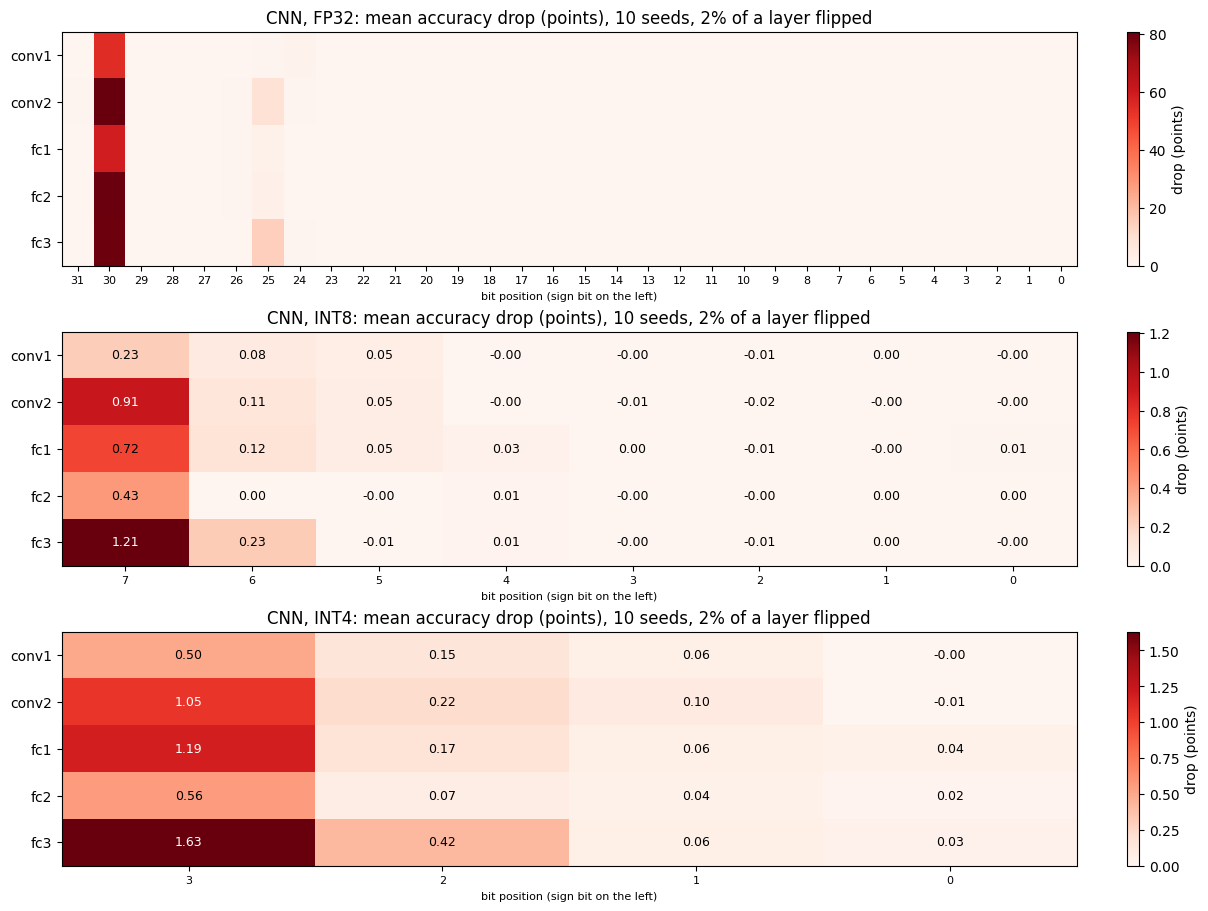

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ===== CODE 8b (resumable): layer x bit sweep with 10 seeds + 95% bootstrap confidence intervals =====
# Re-runs the sweep on the CNN of THIS notebook (so every result comes from one model). Takes ~20-40 minutes.
# If Colab disconnects, run again: it continues where it stopped. Needs Code 1.
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

FRAC, SEEDS = 0.02, range(10)
CK = "cnn_bit_sweep_10seeds.csv"
rows = pd.read_csv(CK).to_dict("records") if os.path.exists(CK) else []     # resume after a disconnect
done = {(r["fmt"], r["layer"]) for r in rows}
print(f"Resuming: {len(done)} of {len(NB) * 5} (format, layer) blocks already finished.")
for fmt, nbits in NB.items():
    clean = acc(build(cnn, fmt))
    for layer in range(5):
        if (fmt, layer) in done:
            continue
        for bit in range(nbits):
            for seed in SEEDS:
                gen = torch.Generator().manual_seed(seed)
                a = acc(build(cnn, fmt, layer, bit, FRAC, gen))
                rows.append(dict(model="cnn", dataset="mnist", fmt=fmt, layer=layer, bit=bit,
                                 seed=seed, frac=FRAC, clean_acc=clean, acc=a, drop=clean - a))
        pd.DataFrame(rows).to_csv(CK, index=False)          # checkpoint after every block
        print(fmt, LAYER_NAMES[layer], "done", flush=True)
df10 = pd.DataFrame(rows)


def boot_ci(x, n=2000, seed=0):
    """95% bootstrap confidence interval of the mean."""
    x = np.asarray(x, dtype=float)
    r = np.random.default_rng(seed)
    means = x[r.integers(0, len(x), (n, len(x)))].mean(1)
    return np.percentile(means, 2.5), np.percentile(means, 97.5)


ci_rows = []
for (fmt, layer, bit), g in df10.groupby(["fmt", "layer", "bit"]):
    lo, hi = boot_ci(g["drop"])
    ci_rows.append(dict(fmt=fmt, layer=LAYER_NAMES[layer], bit=bit, mean_drop=g["drop"].mean(),
                        ci_low=lo, ci_high=hi))
ci = pd.DataFrame(ci_rows).round(2)
ci.to_csv("cnn_bit_ci.csv", index=False)

pd.set_option("display.width", 200)
print("\nCells whose 95% CI lower end is above 1 accuracy point (clearly harmful):")
bad = ci[ci.ci_low > 1.0].sort_values("mean_drop", ascending=False)
print(f"{len(bad)} of {len(ci)} (format, layer, bit) cells")
print(bad.groupby("fmt").size().to_string())

print("\nWorst bit per format, per layer (mean drop with 95% CI):")
for fmt, bit in {"fp32": 30, "int8": 7, "int4": 3}.items():
    t = ci[(ci.fmt == fmt) & (ci.bit == bit)][["layer", "mean_drop", "ci_low", "ci_high"]]
    print(f"\n{fmt.upper()} bit {bit}")
    print(t.to_string(index=False))

# heatmaps, own colour scale per format
fig, axes = plt.subplots(3, 1, figsize=(12, 9), constrained_layout=True)
for ax, fmt in zip(axes, NB):
    t = df10[df10.fmt == fmt].pivot_table(index="layer", columns="bit", values="drop", aggfunc="mean")
    t = t[sorted(t.columns, reverse=True)]
    vmax = max(t.values.max(), 1.0)
    im = ax.imshow(t.values, cmap="Reds", aspect="auto", vmin=0, vmax=vmax)
    ax.set_xticks(range(t.shape[1])); ax.set_xticklabels(t.columns, fontsize=8)
    ax.set_yticks(range(5)); ax.set_yticklabels(LAYER_NAMES)
    ax.set_xlabel("bit position (sign bit on the left)", fontsize=8)
    ax.set_title(f"CNN, {fmt.upper()}: mean accuracy drop (points), 10 seeds, {FRAC * 100:.0f}% of a layer flipped")
    if t.shape[1] <= 8:
        for i in range(t.shape[0]):
            for j in range(t.shape[1]):
                v = t.values[i, j]
                ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=9,
                        color="white" if v > 0.6 * vmax else "black")
    fig.colorbar(im, ax=ax, label="drop (points)")
plt.savefig("cnn_heatmaps_10seeds.png", dpi=200, bbox_inches="tight")
plt.show()

from google.colab import files
files.download("cnn_bit_sweep_10seeds.csv")
files.download("cnn_bit_ci.csv")
files.download("cnn_heatmaps_10seeds.png")

In [ ]:
# EXPORT CELL: run AFTER Code 1 (needs the `cnn` variable). Saves what the website needs.
import os, glob, zipfile
import numpy as np
import torch

assert 'cnn' in globals(), "Run the CNN training code first (it creates the variable `cnn`), then run this cell."
print("=== MODEL (send me this printout) ===")
print(cnn)
print("parameters:", sum(p.numel() for p in cnn.parameters()))

# 1) the trained weights
torch.save({k: v.detach().cpu() for k, v in cnn.state_dict().items()}, "cnn_mnist.pt")

# 2) 500 MNIST test digits
from torchvision import datasets
ds = datasets.MNIST("mnist_export_data", train=False, download=True)
np.savez("mnist_samples.npz", x=ds.data[:500].numpy().astype(np.uint8), y=ds.targets[:500].numpy())

# 3) show the columns of every result CSV (send me this printout)
print("\n=== RESULT CSV FILES ===")
csvs = sorted(set(glob.glob("*.csv") + glob.glob("/content/*.csv") + glob.glob("results/*.csv")))
import pandas as pd
for f in csvs:
    try:
        d = pd.read_csv(f)
        print(f, d.shape, list(d.columns))
    except Exception as e:
        print(f, "could not read:", e)

# 4) one small zip with everything
with zipfile.ZipFile("for_website.zip", "w") as z:
    for f in ["cnn_mnist.pt", "mnist_samples.npz"] + csvs:
        z.write(f, os.path.basename(f))
print("\nSaved for_website.zip (", round(os.path.getsize("for_website.zip") / 1e6, 2), "MB )")
try:
    from google.colab import files
    files.download("for_website.zip")      # if this hangs, use the Files panel on the left: right-click the zip > Download
except Exception as e:
    print("Download from the left Files panel instead:", e)

=== MODEL (send me this printout) ===
Sequential(
  (0): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Flatten(start_dim=1, end_dim=-1)
  (7): Linear(in_features=400, out_features=120, bias=True)
  (8): ReLU()
  (9): Linear(in_features=120, out_features=84, bias=True)
  (10): ReLU()
  (11): Linear(in_features=84, out_features=10, bias=True)
)
parameters: 61706


100%|██████████| 9.91M/9.91M [00:00<00:00, 19.9MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 616kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 5.50MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 4.49MB/s]



=== RESULT CSV FILES ===
paper_matrix.csv (14, 10) ['id', 'paper', 'authors_venue_year', 'model_dataset', 'number_format', 'fault_model', 'metric', 'mitigation', 'limitation_or_relevance_to_my_project', 'how_verified']

Saved for_website.zip ( 0.65 MB )


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
   print([k for k, v in globals().items() if hasattr(v, "state_dict")])

['cnn', 'opt']


In [ ]:
import glob, os, zipfile
csvs = sorted(set(glob.glob("*.csv") + glob.glob("/content/*.csv") + glob.glob("results/*.csv") + glob.glob("/content/**/*.csv", recursive=True)))
for f in csvs: print(f, os.path.getsize(f), "bytes")
with zipfile.ZipFile("results_csvs.zip", "w") as z:
    for f in csvs: z.write(f, os.path.basename(f))
from google.colab import files
files.download("results_csvs.zip")

/content/quantized-bitflip-study/paper_matrix.csv 5653 bytes
/content/sample_data/california_housing_test.csv 301141 bytes
/content/sample_data/california_housing_train.csv 1706430 bytes
/content/sample_data/mnist_test.csv 18289443 bytes
/content/sample_data/mnist_train_small.csv 36523880 bytes
paper_matrix.csv 5653 bytes


/usr/lib/python3.13/zipfile/__init__.py:1686: UserWarning: Duplicate name: 'paper_matrix.csv'
  return self._open_to_write(zinfo, force_zip64=force_zip64)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import glob, os
fs = [f for f in glob.glob("/content/**/*.csv", recursive=True) + glob.glob("**/*.csv", recursive=True) if "sample_data" not in f]
for f in sorted(set(fs)):
    print(f"{os.path.getsize(f)/1e6:8.2f} MB  {f}")

    0.01 MB  /content/quantized-bitflip-study/paper_matrix.csv
    0.01 MB  paper_matrix.csv


In [ ]:
!ls -laR /content/quantized-bitflip-study | head -80
!ls -la /content | head -40
!ls /content/drive/MyDrive 2>/dev/null | head -40


/content/quantized-bitflip-study:
total 55560
drwxr-xr-x 8 root root     4096 Nov 14 09:24 .
drwxr-xr-x 1 root root     4096 Nov 14 09:11 ..
drwxr-xr-x 2 root root     4096 Nov 14 09:11 figures
-rw-r--r-- 1 root root       22 Nov 14 09:24 FILE.csv.zip
-rw-r--r-- 1 root root       60 Oct 25 10:12 .gitignore
drwxr-xr-x 2 root root     4096 Nov 14 09:11 notebooks
-r--r--r-- 1 root root     5653 Oct 25 10:12 paper_matrix.csv
drwxr-xr-x 3 root root     4096 Nov 14 09:11 .pytest_cache
-rw-r--r-- 1 root root     1867 Oct 25 10:12 README.md
-rw-r--r-- 1 root root       43 Oct 25 10:12 requirements.txt
drwxr-xr-x 2 root root     4096 Nov 14 09:11 results
-rw-r--r-- 1 root root 56832922 Nov 14 09:12 results_csvs.zip
drwxr-xr-x 3 root root     4096 Nov 14 09:11 src
drwxr-xr-x 3 root root     4096 Nov 14 09:11 tests

/content/quantized-bitflip-study/figures:
total 8
drwxr-xr-x 2 root root 4096 Nov 14 09:11 .
drwxr-xr-x 8 root root 4096 Nov 14 09:24 ..
-rw-r--r-- 1 root root    0 Oct 25 10:11 .gitk